# OpenAQ - XGBoost

### ***↪***&nbsp;&nbsp;**Imports**

In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

In [2]:
# ================================================================
# INPUTS: change depending on the data you're working with

import os
from openaq_anomaly_prediction.config import Configuration as cfg

PARQUET_FILEPATH = os.path.join(cfg.DATA_EXPORT_PATH, "bq_int_openaq__measurements_standardized.parquet")
# PARQUET_FILEPATH = os.path.join(cfg.DATA_EXPORT_PATH, "seoul_complete.int.parquet")
# PARQUET_FILEPATH = os.path.join("seoul_complete.int.parquet")

In [3]:
%load_ext autoreload
%autoreload 2

from openaq_anomaly_prediction.load.gcp import bq

In [4]:
%load_ext autoreload
%autoreload 2

from sklearn.base import BaseEstimator
from openaq_anomaly_prediction.core.xgboost import CustomXGBoostModel
from openaq_anomaly_prediction.core.timeseries_utils import tsu

import random
import tempfile
from pathlib import Path

import duckdb
import pandas as pd
from utilsforecast.plotting import plot_series
from utilsforecast.losses import rmse, mae, mape
from utilsforecast.evaluation import evaluate
import xgboost as xgb
import lightgbm as lgb
from mlforecast import MLForecast
from mlforecast.lag_transforms import ExpandingMean, RollingMean
from mlforecast.lag_transforms import (
    RollingMean,
    RollingStd,
    SeasonalRollingMean,
    SeasonalRollingStd,
    ExponentiallyWeightedMean,
    RollingMax,
    ExpandingStd,
)
from mlforecast.target_transforms import (
    Differences,
    LocalRobustScaler,
    LocalMinMaxScaler,
    LocalStandardScaler,
    LocalBoxCox,
)
from sklearn.preprocessing import FunctionTransformer

import mlforecast

import optuna
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


class Naive(BaseEstimator):
    def fit(self, X, y):
        return self

    def predict(self, X):
        return X["lag1"]

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [5]:
# ================================================================
# IMPORTS: python packages and settings (don't change anything)

import time
import requests
import gc
from typing_extensions import Literal

import duckdb
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import pyarrow.dataset as ds
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from plotly.graph_objs import Figure as PlotlyFigure

from pprint import pprint

# CONFIG: to display all rows/columns of a dataframe (debug)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 1000)
SEP_LENGTH = 64  # Only so we can print separators of a fixed length

# PyArrow
parquet_file = pq.ParquetFile(PARQUET_FILEPATH)

# DuckDB:
con = duckdb.connect()
con.execute("SET TimeZone = 'UTC';")
con.execute(
    f"CREATE OR REPLACE VIEW raw_measurements AS SELECT * FROM read_parquet('{PARQUET_FILEPATH}')"
)

In [6]:
# ================================================================
# UTILS: helper functions (don't change anything)

def print_summary_request(df: pd.DataFrame, start_time: float, **kwargs) -> None:
    """Print a summary of a request."""

    # title = kwargs.get("title", "Measurements DataFrame")
    sep_length = kwargs.get("sep_length", 64)    
    end = kwargs.get("end", "")    
    
    if df is None:
        print(f"> [BigQuery]: Request returned no data.{end}")
        return
    
    memory_usage = df.memory_usage(index=True, deep=True).sum() / (1024**2)

    # Summary
    # print(f"{'='*sep_length}\nSUMMARY: {title}\n{'-'*sep_length}")
    print(f"> [BigQuery]: Request finished in {time.perf_counter() - start_time:.2f}s  ->  {len(df):,} rows, {memory_usage:.2f} MB{end}")

    # # Date range
    # print_datetime = False
    # if "datetimeto_local" in df.columns:
    #     datetime_column = "datetimeto_local"
    #     print_datetime = True
    # elif "ds" in df.columns:
    #     datetime_column = "ds"
    #     print_datetime = True
    # elif "datetimeto_utc" in df.columns:
    #     datetime_column = "datetimeto_utc"
    #     print_datetime = True
    # if print_datetime:
    #     print(f"From: {df[datetime_column].min()} ({datetime_column})")
    #     print(f"To  : {df[datetime_column].max()} ({datetime_column})")

    # # Unique locations
    # if "location_id" in df.columns or "unique_id" in df.columns:
    #     location_id_column = "location_id" if "location_id" in df.columns else "unique_id"
    #     print(f"{'-'*int(sep_length/3)*2}")
    #     print(f"Unique locations: {df[location_id_column].nunique()}")

def print_summary_measurements(df: pd.DataFrame, **kwargs) -> None:
    """Print a summary of the useful stats of a measurements dataframe."""

    title = kwargs.get("title", "Measurements DataFrame")
    sep_length = kwargs.get("sep_length", 64)    
    disable_pollutants = kwargs.get("disable_pollutants", False)    
    
    memory_usage = df.memory_usage(index=True, deep=True).sum() / (1024**2)

    # Summary
    print(f"{'='*sep_length}\nSUMMARY: {title}\n{'-'*sep_length}")
    print(f"Total rows  : {len(df):,}")
    print(f"Memory usage: {memory_usage:.2f} MB")

    # Date range
    if "datetimeto_local" in df.columns:
        datetime_column = "datetimeto_local"
    elif "ds" in df.columns:
        datetime_column = "ds"
    else:
        datetime_column = "datetimeto_utc"
    print(f"From: {df[datetime_column].min()} ({datetime_column})")
    print(f"To  : {df[datetime_column].max()} ({datetime_column})")

    # Unique locations
    location_id_column = "location_id" if "location_id" in df.columns else "unique_id"
    print(f"{'-'*int(sep_length/3)*2}")
    print(f"Unique locations: {df[location_id_column].nunique()}")

    # Unique pollutants
    if "sensor_name" in df.columns and not disable_pollutants:
        print(f"Unique pollutants: {df["sensor_name"].nunique()}")
        print(f"{'-'*int(sep_length/3)*1}")
        for pollutant in df["sensor_name"].unique():
            print(f"> {pollutant}")

### ***↪***&nbsp;&nbsp;**Sandbox**

In [ ]:
# # ================================================================
# # BIG QUERY REQUESTS: run your queries here

# # BigQuery
# start_time = time.perf_counter()
# query = """
#     SELECT
#         *
#     FROM `openaq-anomaly-prediction.dev_staging.stg_openmeteo__historical`
#     WHERE datetimeto_utc <= '2026-01-01' AND datetimeto_utc >= '2025-12-31'
#     ORDER BY location_id, datetimeto_utc DESC
# """
# query_parameters = [
#     # ("test_locations_ids", "STRING", TEST_LOCATIONS)
# ]
# test_df = bq.query(query, query_parameters=query_parameters, dry_run=False)
# print_summary_request(test_df, start_time)

# # Results
# if test_df is not None:
#     display(test_df.head(10))
#     display(test_df.info())

In [ ]:
# display(test_df[["location_id", "datetimeto_utc", "datetimeto_local", "is_day"]].head(50))

In [ ]:
# ================================================================
# BIG QUERY REQUESTS: run your queries here

def get_train_df():
    # BigQuery
    start_time = time.perf_counter()
    query = """
        SELECT
            *
        FROM `openaq-anomaly-prediction.dev_serving.ml_seoul__xgb_train`
        WHERE datetimeto_utc <= '2026-01-01'
        --  AND datetimeto_utc >= '2025-12-15'
        ORDER BY location_id, datetimeto_utc ASC
    """
    query_parameters = [
        # ("test_locations_ids", "STRING", TEST_LOCATIONS)
    ]
    train_df = bq.query(query, query_parameters=query_parameters, dry_run=False)
    print_summary_request(train_df, start_time)
    print_summary_measurements(train_df)

    # Results
    if train_df is not None:
        display(train_df.head(10))
        display(train_df.info())

In [ ]:
# ================================================================
# BIG QUERY REQUESTS: run your queries here

def fetch_dataset(dataset_type: Literal["train", "test"], **kwargs):
    
    debug = kwargs.get("debug", False)
    
    if dataset not in ["train", "test"]:
        raise ValueError("dataset must be either 'train' or 'test'")

    # TODO: Put a local cache mechanism here (parquet file)

    # BigQuery
    start_time = time.perf_counter()
    query = f"""
        SELECT
            *
        FROM `openaq-anomaly-prediction.dev_serving.ml_seoul__xgb_{dataset}`
        WHERE datetimeto_utc <= '2026-01-01'
        --  AND datetimeto_utc >= '2025-12-15'
        ORDER BY location_id, datetimeto_utc ASC
    """
    query_parameters = [
        # ("dataset", "STRING", dataset)
    ]
    df = bq.query(query, query_parameters=query_parameters, dry_run=False)
    
    if debug:
        print_summary_request(df, start_time)
        print_summary_measurements(df)

        # Results
        if df is not None:
            display(df.head(10))
            display(df.info())
            
    return df

In [ ]:
# test_df = fetch_dataset("test", debug=False)

In [ ]:
def ml_check_nans(df: pd.DataFrame) -> None:
    """Check for NaNs in the dataframe and print the results."""
    
    target_columns = ["pm25_ugm3", "pm10_ugm3", "no2_ppm", "o3_ppm", "so2_ppm", "co_ppm"]
    openmeteo_columns = [col for col in df.columns if col.startswith("om_")]
    other_columns = [col for col in df.columns if col not in target_columns + openmeteo_columns]

    # Target columns NaN analysis
    nan_target_columns = df[target_columns].isna().sum().sort_values(ascending=False)
    print(f"NaN values in the target columns: {nan_target_columns.sum()}")
    print(nan_target_columns)

    # OpenMeteo columns NaN analysis
    nan_openmeteo_columns = df[openmeteo_columns].isna().sum().sort_values(ascending=False)
    print(f"\nNaN values in OpenMeteo columns: {nan_openmeteo_columns.sum()}")
    print(nan_openmeteo_columns)

    # Other columns NaN analysis
    nan_other_columns = df[other_columns].isna().sum().sort_values(ascending=False)
    print(f"\nNaN values in other columns: {nan_other_columns.sum()}")
    print(nan_other_columns)

### ***↪***&nbsp;&nbsp;**XGBoost - Data Prep**

#### Load the Train dataset

In [27]:
custom_xgb = CustomXGBoostModel()
train = custom_xgb.load_train_dataset()

10:32:09      DEBUG |  [TRAIN] Loading training dataset for XGBoost model.
10:32:29      TRACE |   󰘍 Loaded 827,907 rows from 99 locations in 20.10s.


In [ ]:
# ================================================================
# FILTER LOCATIONS SO WE CAN TEST FASTER

print(f"{'=' * 64}\nFILTERING LOCATIONS (ONLY USE 25% FOR SPEED)\n{'-' * 64}")
print(f"Before filtering locations: {len(train['location_id'].unique())} unique locations, {len(train)} rows.")
custom_xgb.print_nan_report(train)

locations_ids = train["location_id"].unique()
# train_df = train[train["location_id"].isin(locations_ids[:len(locations_ids)//4])].copy()
train_df = train[train["location_id"].isin(locations_ids[:len(locations_ids)])].copy()


print(f"\n{'-' * 64}")
print(f"After filtering locations: {len(train_df['location_id'].unique())} unique locations, {len(train_df)} rows.")
custom_xgb.print_nan_report(train_df)

FILTERING LOCATIONS (ONLY USE 25% FOR SPEED)
----------------------------------------------------------------
Before filtering locations: 99 unique locations, 827907 rows.

[ TARGET    ]: 79278 NaN values in the target columns
pm25_ugm3    17062
pm10_ugm3    14347
co_ppm       12253
so2_ppm      12213
no2_ppm      11742
o3_ppm       11661
dtype: int64

[ OPENAQ    ]: 0 NaN values in OpenAQ columns
[ OPENMETEO ]: 0 NaN values in OpenMeteo columns
[ FEATURES  ]: 3472742 NaN values in features columns
feat_pollutant__lag168_pm25_pm10_index            132234
feat_pollutant__lag168_pm25_ugm3                  129647
feat_pollutant__lag168_pm10_ugm3                  127360
feat_pollutant__lag168_no2_co_index               125844
feat_pollutant__lag168_co_ppm                     125646
feat_weather__sulfate_potential_lag168            125630
feat_pollutant__lag168_so2_ppm                    125630
feat_pollutant__lag168_no2_ppm                    125219
feat_weather__nitrate_potential_lag168  

In [29]:
# ================================================================
# INTERPOLATE ALL POLLUTANTS
 
train_df = custom_xgb.interpolate_pollutants(train_df, debug=True)
custom_xgb.print_nan_report(train_df)

INTERPOLATING 6 POLLUTANTS
----------------------------------------------------------------
BEFORE: 79278 total NaN values
    -> Adding columns       : ['pm25_ugm3_is_imputed', 'pm10_ugm3_is_imputed', 'no2_ppm_is_imputed', 'o3_ppm_is_imputed', 'so2_ppm_is_imputed', 'co_ppm_is_imputed', 'any_imputed']
    -> Grouped by           : ['location_id', 'segment_id']
    -> Linear interpolation : up to 4 hours
    -> Forward fill         : up to 4 hours
    -> Backward fill        : up to 4 hours
AFTER: 0 total NaN values

[ TARGET    ]: 0 NaN values in the target columns
[ OPENAQ    ]: 0 NaN values in OpenAQ columns
[ OPENMETEO ]: 0 NaN values in OpenMeteo columns
[ FEATURES  ]: 3472742 NaN values in features columns
feat_pollutant__lag168_pm25_pm10_index            132234
feat_pollutant__lag168_pm25_ugm3                  129647
feat_pollutant__lag168_pm10_ugm3                  127360
feat_pollutant__lag168_no2_co_index               125844
feat_pollutant__lag168_co_ppm                     1

In [30]:
# ================================================================
# COLUMNS CATEGORIZATION
 
display(train_df.head(1))
custom_xgb.print_categories_report()

,location_id,datetimeto_utc,segment_id,segment_start,segment_end,segment_perfect_hours,segment_total_hours,segment_perfect_density,segment_tier,segments_num,segments_total,pm25_ugm3,pm10_ugm3,no2_ppm,o3_ppm,so2_ppm,co_ppm,oaq_datetimeto_local,oaq_ismonitor,oaq_owner_id,oaq_provider_id,oaq_latitude,oaq_longitude,om_elevation,om_temperature_2m,om_relative_humidity_2m,om_dew_point_2m,om_precipitation,om_rain,om_snowfall,om_snow_depth,om_shortwave_radiation,om_direct_radiation,om_diffuse_radiation,om_weather_code,om_pressure_msl,om_cloud_cover,om_cloud_cover_low,om_cloud_cover_mid,om_cloud_cover_high,om_vapour_pressure_deficit,om_wind_speed_100m,om_wind_speed_10m,om_wind_direction_10m,om_wind_gusts_10m,om_is_day,feat_time__hour,feat_time__dow,feat_time__month,feat_time__hour_sin_k1,feat_time__hour_cos_k1,feat_time__hour_sin_k2,feat_time__hour_cos_k2,feat_time__hour_sin_k3,feat_time__hour_cos_k3,feat_time__dow_sin_k1,feat_time__dow_cos_k1,feat_time__month_sin_k1,feat_time__month_cos_k1,feat_time__is_rush_hour,feat_time__is_weekend,feat_time__is_party_night,feat_time__is_yellow_dust_season,feat_time__is_moonsoon_season,feat_time__is_winter_season,feat_time__is_summer_break,feat_time__is_winter_break,feat_time__is_spring_break,feat_time__is_school_break,feat_pollutant__expmean_pm25_ugm3,feat_pollutant__expmean_pm10_ugm3,feat_pollutant__expmean_no2_ppm,feat_pollutant__expmean_o3_ppm,feat_pollutant__expmean_so2_ppm,feat_pollutant__expmean_co_ppm,feat_pollutant__roll720_mean_pm25_ugm3,feat_pollutant__roll720_mean_pm10_ugm3,feat_pollutant__roll720_mean_no2_ppm,feat_pollutant__roll720_mean_o3_ppm,feat_pollutant__roll720_mean_so2_ppm,feat_pollutant__roll720_mean_co_ppm,feat_pollutant__lag168_pm25_ugm3,feat_pollutant__lag168_pm10_ugm3,feat_pollutant__lag168_no2_ppm,feat_pollutant__lag168_o3_ppm,feat_pollutant__lag168_so2_ppm,feat_pollutant__lag168_co_ppm,feat_pollutant__lag168_roll24_mean_pm25_ugm3,feat_pollutant__lag168_roll24_mean_pm10_ugm3,feat_pollutant__lag168_roll24_mean_no2_ppm,feat_pollutant__lag168_roll24_mean_o3_ppm,feat_pollutant__lag168_roll24_mean_so2_ppm,feat_pollutant__lag168_roll24_mean_co_ppm,feat_pollutant__lag168_roll24_stddev_pm25_ugm3,feat_pollutant__lag168_roll24_stddev_pm10_ugm3,feat_pollutant__lag168_roll24_stddev_no2_ppm,feat_pollutant__lag168_roll24_stddev_o3_ppm,feat_pollutant__lag168_roll24_stddev_so2_ppm,feat_pollutant__lag168_roll24_stddev_co_ppm,feat_pollutant__lag168_roll24_max_pm25_ugm3,feat_pollutant__lag168_roll24_max_pm10_ugm3,feat_pollutant__lag168_roll24_max_no2_ppm,feat_pollutant__lag168_roll24_max_o3_ppm,feat_pollutant__lag168_roll24_max_so2_ppm,feat_pollutant__lag168_roll24_max_co_ppm,feat_pollutant__lag168_pm25_pm10_index,feat_pollutant__lag168_no2_co_index,feat_weather__wind_direction_10m_sin,feat_weather__wind_direction_10m_cos,feat_weather__washout_index,feat_weather__moisture_trap_index,feat_weather__atmos_stability_index,feat_weather__moisture_saturation_index,feat_weather__dew_point_depression,feat_weather__photolytic_flux_index,feat_weather__wind_burst_ratio_index_10m,feat_weather__o3_potential_lag168,feat_weather__sulfate_potential_lag168,feat_weather__nitrate_potential_lag168,feat_weather__lag1_precipitation,feat_weather__delta1_pressure_msl,feat_weather__delta3_temperature_2m,pm25_ugm3_is_imputed,pm10_ugm3_is_imputed,no2_ppm_is_imputed,o3_ppm_is_imputed,so2_ppm_is_imputed,co_ppm_is_imputed,any_imputed
0,2622586,2024-05-16 01:00:00+00:00,2622586_S2,2024-05-16 01:00:00+00:00,2024-07-04 05:00:00+00:00,1137,1181,0.962743,gold,2,62,5.0,23.0,0.0184,0.0248,0.0025,0.4,2024-05-16 10:00:00,True,4,69,37.580167,127.044856,20.0,13.2,68,7.5,0.0,0.0,0.0,0.0,673.0,503.0,170.0,0,1011.3,0,0,0,0,0.49,13.3,10.5,301,22.3,1,10,3,4,0.5,-0.866025,-0.866025,0.5,1.0,1.194340e-15,0.433884,-0.900969,0.866025,-0.5,0,0,0,1,0,0,0,0,0,0,15.183844,32.509749,0.02298,0.040603,0.002923,0.401176,15.183844,32.509749,0.02298,0.040603,0.002923,0.401176,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N

COLUMNS CATEGORIZATION

Pollutants columns (6):
['pm25_ugm3', 'pm10_ugm3', 'no2_ppm', 'o3_ppm', 'so2_ppm', 'co_ppm']

OpenAQ columns (6):
['oaq_datetimeto_local', 'oaq_ismonitor', 'oaq_owner_id', 'oaq_provider_id', 'oaq_latitude', 'oaq_longitude']

OpenMeteo columns (23):
['om_elevation', 'om_temperature_2m', 'om_relative_humidity_2m', 'om_dew_point_2m', 'om_precipitation', 'om_rain', 'om_snowfall', 'om_snow_depth', 'om_shortwave_radiation', 'om_direct_radiation', 'om_diffuse_radiation', 'om_weather_code', 'om_pressure_msl', 'om_cloud_cover', 'om_cloud_cover_low', 'om_cloud_cover_mid', 'om_cloud_cover_high', 'om_vapour_pressure_deficit', 'om_wind_speed_100m', 'om_wind_speed_10m', 'om_wind_direction_10m', 'om_wind_gusts_10m', 'om_is_day']

Segments columns (9):
['segment_id', 'segment_start', 'segment_end', 'segment_perfect_hours', 'segment_total_hours', 'segment_perfect_density', 'segment_tier', 'segments_num', 'segments_total']

Features columns (76):
 > Time features (23)      : ['fe

In [31]:
# Plot an histogram of the segment_total_hours column over each segment_id
print(f"{'=' * 64}\nSEGMENT HOURS DISTRIBUTION\n{'-' * 64}")

segments_duration = train_df.groupby('segment_id')['segment_total_hours'].first().reset_index()
segments_duration.head()

print(f"Total segments: {segments_duration["segment_id"].nunique()}")

segments_336 = segments_duration[segments_duration["segment_total_hours"] >= 336]
segments_count_336 = len(segments_336)
segments_rows_336 = segments_336["segment_total_hours"].sum()
print(f"Total segments >= 336 hours: {segments_count_336} => {segments_rows_336:,} hours")

segments_432 = segments_duration[segments_duration["segment_total_hours"] >= 432]
segments_count_432 = len(segments_432)
segments_rows_432 = segments_432["segment_total_hours"].sum()
print(f"Total segments >= 432 hours: {segments_count_432} => {segments_rows_432:,} hours")

segments_504 = segments_duration[segments_duration["segment_total_hours"] >= 504]
segments_count_504 = len(segments_504)
segments_rows_504 = segments_504["segment_total_hours"].sum()
print(f"Total segments >= 504 hours: {segments_count_504} => {segments_rows_504:,} hours")

segments_604 = segments_duration[segments_duration["segment_total_hours"] >= 604]
segments_count_604 = len(segments_604)
segments_rows_604 = segments_604["segment_total_hours"].sum()
print(f"Total segments >= 604 hours: {segments_count_604} => {segments_rows_604:,} hours")

segments_1344 = segments_duration[segments_duration["segment_total_hours"] >= 1344]
segments_count_1344 = len(segments_1344)
segments_rows_1344 = segments_1344["segment_total_hours"].sum()
print(f"Total segments >= 1344 hours: {segments_count_1344} => {segments_rows_1344:,} hours")

SEGMENT HOURS DISTRIBUTION
----------------------------------------------------------------
Total segments: 685
Total segments >= 336 hours: 685 => 828,885 hours
Total segments >= 432 hours: 685 => 828,885 hours
Total segments >= 504 hours: 685 => 828,885 hours
Total segments >= 604 hours: 595 => 779,180 hours
Total segments >= 1344 hours: 203 => 425,970 hours


#### Test the custom preprocessor

In [17]:
# ================================================================
# COLUMNS CATEGORIZATION
 
display(train_df.head(1))
# display(train_df.info())

custom_xgb.print_categories_report()

,location_id,datetimeto_utc,segment_id,segment_start,segment_end,segment_perfect_hours,segment_total_hours,segment_perfect_density,segment_tier,segments_num,segments_total,pm25_ugm3,pm10_ugm3,no2_ppm,o3_ppm,so2_ppm,co_ppm,oaq_datetimeto_local,oaq_ismonitor,oaq_owner_id,oaq_provider_id,oaq_latitude,oaq_longitude,om_elevation,om_temperature_2m,om_relative_humidity_2m,om_dew_point_2m,om_precipitation,om_rain,om_snowfall,om_snow_depth,om_shortwave_radiation,om_direct_radiation,om_diffuse_radiation,om_weather_code,om_pressure_msl,om_cloud_cover,om_cloud_cover_low,om_cloud_cover_mid,om_cloud_cover_high,om_vapour_pressure_deficit,om_wind_speed_100m,om_wind_speed_10m,om_wind_direction_10m,om_wind_gusts_10m,om_is_day,feat_time__hour,feat_time__dow,feat_time__month,feat_time__hour_sin_k1,feat_time__hour_cos_k1,feat_time__hour_sin_k2,feat_time__hour_cos_k2,feat_time__hour_sin_k3,feat_time__hour_cos_k3,feat_time__dow_sin_k1,feat_time__dow_cos_k1,feat_time__month_sin_k1,feat_time__month_cos_k1,feat_time__is_rush_hour,feat_time__is_weekend,feat_time__is_party_night,feat_time__is_yellow_dust_season,feat_time__is_moonsoon_season,feat_time__is_winter_season,feat_time__is_summer_break,feat_time__is_winter_break,feat_time__is_spring_break,feat_time__is_school_break,feat_pollutant__expmean_pm25_ugm3,feat_pollutant__expmean_pm10_ugm3,feat_pollutant__expmean_no2_ppm,feat_pollutant__expmean_o3_ppm,feat_pollutant__expmean_so2_ppm,feat_pollutant__expmean_co_ppm,feat_pollutant__roll720_mean_pm25_ugm3,feat_pollutant__roll720_mean_pm10_ugm3,feat_pollutant__roll720_mean_no2_ppm,feat_pollutant__roll720_mean_o3_ppm,feat_pollutant__roll720_mean_so2_ppm,feat_pollutant__roll720_mean_co_ppm,feat_pollutant__lag168_pm25_ugm3,feat_pollutant__lag168_pm10_ugm3,feat_pollutant__lag168_no2_ppm,feat_pollutant__lag168_o3_ppm,feat_pollutant__lag168_so2_ppm,feat_pollutant__lag168_co_ppm,feat_pollutant__lag168_roll24_mean_pm25_ugm3,feat_pollutant__lag168_roll24_mean_pm10_ugm3,feat_pollutant__lag168_roll24_mean_no2_ppm,feat_pollutant__lag168_roll24_mean_o3_ppm,feat_pollutant__lag168_roll24_mean_so2_ppm,feat_pollutant__lag168_roll24_mean_co_ppm,feat_pollutant__lag168_roll24_stddev_pm25_ugm3,feat_pollutant__lag168_roll24_stddev_pm10_ugm3,feat_pollutant__lag168_roll24_stddev_no2_ppm,feat_pollutant__lag168_roll24_stddev_o3_ppm,feat_pollutant__lag168_roll24_stddev_so2_ppm,feat_pollutant__lag168_roll24_stddev_co_ppm,feat_pollutant__lag168_roll24_max_pm25_ugm3,feat_pollutant__lag168_roll24_max_pm10_ugm3,feat_pollutant__lag168_roll24_max_no2_ppm,feat_pollutant__lag168_roll24_max_o3_ppm,feat_pollutant__lag168_roll24_max_so2_ppm,feat_pollutant__lag168_roll24_max_co_ppm,feat_pollutant__lag168_pm25_pm10_index,feat_pollutant__lag168_no2_co_index,feat_weather__wind_direction_10m_sin,feat_weather__wind_direction_10m_cos,feat_weather__washout_index,feat_weather__moisture_trap_index,feat_weather__atmos_stability_index,feat_weather__moisture_saturation_index,feat_weather__dew_point_depression,feat_weather__photolytic_flux_index,feat_weather__wind_burst_ratio_index_10m,feat_weather__o3_potential_lag168,feat_weather__sulfate_potential_lag168,feat_weather__nitrate_potential_lag168,feat_weather__lag1_precipitation,feat_weather__delta1_pressure_msl,feat_weather__delta3_temperature_2m,pm25_ugm3_is_imputed,pm10_ugm3_is_imputed,no2_ppm_is_imputed,o3_ppm_is_imputed,so2_ppm_is_imputed,co_ppm_is_imputed,any_imputed
0,2622586,2024-04-30 15:00:00+00:00,2622586_S1,2024-04-30 15:00:00+00:00,2024-05-15 15:00:00+00:00,357,361,0.98892,gold,1,62,43.0,68.0,0.0328,0.0264,0.0036,0.56,2024-05-01,True,4,69,37.580167,127.044856,20.0,13.6,74,9.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3,1009.9,100,91,89,100,0.4,23.7,12.8,74,20.5,0,0,2,4,0.0,1.0,0.0,1.0,0.0,1.0,0.974928,-0.222521,0.866025,-0.5,0,0,0,1,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.961262,0.275637,0.0,5838.484375,78.898438,2.0,4.5,0.0,1.601562,NaN,

COLUMNS CATEGORIZATION

Pollutants columns (6):
['pm25_ugm3', 'pm10_ugm3', 'no2_ppm', 'o3_ppm', 'so2_ppm', 'co_ppm']

OpenAQ columns (6):
['oaq_datetimeto_local', 'oaq_ismonitor', 'oaq_owner_id', 'oaq_provider_id', 'oaq_latitude', 'oaq_longitude']

OpenMeteo columns (23):
['om_elevation', 'om_temperature_2m', 'om_relative_humidity_2m', 'om_dew_point_2m', 'om_precipitation', 'om_rain', 'om_snowfall', 'om_snow_depth', 'om_shortwave_radiation', 'om_direct_radiation', 'om_diffuse_radiation', 'om_weather_code', 'om_pressure_msl', 'om_cloud_cover', 'om_cloud_cover_low', 'om_cloud_cover_mid', 'om_cloud_cover_high', 'om_vapour_pressure_deficit', 'om_wind_speed_100m', 'om_wind_speed_10m', 'om_wind_direction_10m', 'om_wind_gusts_10m', 'om_is_day']

Segments columns (9):
['segment_id', 'segment_start', 'segment_end', 'segment_perfect_hours', 'segment_total_hours', 'segment_perfect_density', 'segment_tier', 'segments_num', 'segments_total']

Features columns (76):
 > Time features (23)      : ['fe

In [26]:
# # ================================================================
# # TEST THE PREPROCESSING PIPELINE IN ISOLATION

# def test_preprocessing_pipeline(train_df: pd.DataFrame) -> None:
#     """Test the preprocessing pipeline of the model."""
    
#     target_pollutant = "pm25_ugm3"

#     # Simulate MLForecast input
#     X_simulated = train_df.copy().rename(
#         columns={"segment_id": "unique_id", "datetimeto_utc": "ds", target_pollutant: "y"}
#     ).drop(
#         columns=["unique_id", "ds", "y"]
#         + CustomXGBoostModel.get_other_pollutant_columns(target_pollutant)
#     )

#     # Preprocess the data (without the model)
#     simulated_model = custom_xgb.create_xgb_model(X_simulated, target_pollutant)
#     preprocessor = simulated_model.named_steps["preprocessor"]
#     transformed_data = preprocessor.fit_transform(X_simulated)

#     # Results
#     print(f"{'=' * 64}\nPREPROCESSING PIPELINE TEST\n{'-' * 64}")
#     print(f"Original Input Shape     : {X_simulated.shape}")
#     print(f"Transformed Output Shape : {transformed_data.shape}")

#     try:
#         feature_names = preprocessor.get_feature_names_out()
#         print("\nGenerated Features :")
#         max_index_length = len(str(len(feature_names) - 1))
#         for i, name in enumerate(feature_names):
#             print(f"{i:<{max_index_length}}: {name}")
#     except Exception as e:
#         print(f"Could not retrieve feature names: {e}")
        
# test_preprocessing_pipeline(train_df)


In [ ]:
# custom_xgb.categorize_columns(train_df)
# model = custom_xgb.create_xgb_model(train_df, "pm25_ugm3")

#### EDA the TS

In [11]:
# ================================================================
# CREATE A NIXTLA DATAFRAME FOR PM2.5

y = "pm25_ugm3"
y = "co_ppm"
ds = "datetimeto_utc"
unique_id = "segment_id"

train_ts = train_df.copy()

train_ts = train_ts.rename(columns={ds: "ds", unique_id: "unique_id", y: "y",})

print(train_ts.shape)
display(train_ts.head())

(940482, 129)


,location_id,ds,unique_id,segment_start,segment_end,segment_perfect_hours,segment_total_hours,segment_perfect_density,segment_tier,segments_num,segments_total,pm25_ugm3,pm10_ugm3,no2_ppm,o3_ppm,so2_ppm,y,oaq_datetimeto_local,oaq_ismonitor,oaq_owner_id,oaq_provider_id,oaq_latitude,oaq_longitude,om_elevation,om_temperature_2m,om_relative_humidity_2m,om_dew_point_2m,om_precipitation,om_rain,om_snowfall,om_snow_depth,om_shortwave_radiation,om_direct_radiation,om_diffuse_radiation,om_weather_code,om_pressure_msl,om_cloud_cover,om_cloud_cover_low,om_cloud_cover_mid,om_cloud_cover_high,om_vapour_pressure_deficit,om_wind_speed_100m,om_wind_speed_10m,om_wind_direction_10m,om_wind_gusts_10m,om_is_day,feat_time__hour,feat_time__dow,feat_time__month,feat_time__hour_sin_k1,feat_time__hour_cos_k1,feat_time__hour_sin_k2,feat_time__hour_cos_k2,feat_time__hour_sin_k3,feat_time__hour_cos_k3,feat_time__dow_sin_k1,feat_time__dow_cos_k1,feat_time__month_sin_k1,feat_time__month_cos_k1,feat_time__is_rush_hour,feat_time__is_weekend,feat_time__is_party_night,feat_time__is_yellow_dust_season,feat_time__is_moonsoon_season,feat_time__is_winter_season,feat_time__is_summer_break,feat_time__is_winter_break,feat_time__is_spring_break,feat_time__is_school_break,feat_pollutant__expmean_pm25_ugm3,feat_pollutant__expmean_pm10_ugm3,feat_pollutant__expmean_no2_ppm,feat_pollutant__expmean_o3_ppm,feat_pollutant__expmean_so2_ppm,feat_pollutant__expmean_co_ppm,feat_pollutant__roll720_mean_pm25_ugm3,feat_pollutant__roll720_mean_pm10_ugm3,feat_pollutant__roll720_mean_no2_ppm,feat_pollutant__roll720_mean_o3_ppm,feat_pollutant__roll720_mean_so2_ppm,feat_pollutant__roll720_mean_co_ppm,feat_pollutant__lag168_pm25_ugm3,feat_pollutant__lag168_pm10_ugm3,feat_pollutant__lag168_no2_ppm,feat_pollutant__lag168_o3_ppm,feat_pollutant__lag168_so2_ppm,feat_pollutant__lag168_co_ppm,feat_pollutant__lag168_roll24_mean_pm25_ugm3,feat_pollutant__lag168_roll24_mean_pm10_ugm3,feat_pollutant__lag168_roll24_mean_no2_ppm,feat_pollutant__lag168_roll24_mean_o3_ppm,feat_pollutant__lag168_roll24_mean_so2_ppm,feat_pollutant__lag168_roll24_mean_co_ppm,feat_pollutant__lag168_roll24_stddev_pm25_ugm3,feat_pollutant__lag168_roll24_stddev_pm10_ugm3,feat_pollutant__lag168_roll24_stddev_no2_ppm,feat_pollutant__lag168_roll24_stddev_o3_ppm,feat_pollutant__lag168_roll24_stddev_so2_ppm,feat_pollutant__lag168_roll24_stddev_co_ppm,feat_pollutant__lag168_roll24_max_pm25_ugm3,feat_pollutant__lag168_roll24_max_pm10_ugm3,feat_pollutant__lag168_roll24_max_no2_ppm,feat_pollutant__lag168_roll24_max_o3_ppm,feat_pollutant__lag168_roll24_max_so2_ppm,feat_pollutant__lag168_roll24_max_co_ppm,feat_pollutant__lag168_pm25_pm10_index,feat_pollutant__lag168_no2_co_index,feat_weather__wind_direction_10m_sin,feat_weather__wind_direction_10m_cos,feat_weather__washout_index,feat_weather__moisture_trap_index,feat_weather__atmos_stability_index,feat_weather__moisture_saturation_index,feat_weather__dew_point_depression,feat_weather__photolytic_flux_index,feat_weather__wind_burst_ratio_index_10m,feat_weather__o3_potential_lag168,feat_weather__sulfate_potential_lag168,feat_weather__nitrate_potential_lag168,feat_weather__lag1_precipitation,feat_weather__delta1_pressure_msl,feat_weather__delta3_temperature_2m,pm25_ugm3_is_imputed,pm10_ugm3_is_imputed,no2_ppm_is_imputed,o3_ppm_is_imputed,so2_ppm_is_imputed,co_ppm_is_imputed,any_imputed
0,2622586,2024-04-30 15:00:00+00:00,2622586_S1,2024-04-30 15:00:00+00:00,2024-05-15 15:00:00+00:00,357,361,0.98892,gold,1,62,43.0,68.0,0.0328,0.0264,0.0036,0.56,2024-05-01 00:00:00,True,4,69,37.580167,127.044856,20.0,13.6,74,9.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3,1009.9,100,91,89,100,0.40,23.7,12.8,74,20.5,0,0,2,4,0.000000,1.000000,0.000000,1.000000e+00,0.000000e+00,1.000000e+00,0.974928,-0.222521,0.866025,-0.5,0,0,0,1,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.961262,0.275637,0.0,5838.484375,7

In [12]:
# ================================================================
# GET A RANDOM SEGMENT FOR EDA

barebone_columns = ["unique_id", "ds", "y"]
random_segments = np.random.choice(
    train_ts["unique_id"].unique(), size=1, replace=False
)
print(f"Random segment: {random_segments}")

rd_train_ts = (
    train_ts[train_ts["unique_id"].isin(random_segments)][barebone_columns].copy().sort_values(by=["ds"])
)

Random segment: ['2623191_S3']


[ GOOD ] ADF ANALYSIS FOR Diff [1]
----------------------------------------------------------------
ADF Statistic      : -10.8093 (p-value: 1.9274e-19 < 1%)
Critical Value 1%  :  -3.4365 [OK]
Critical Value 5%  :  -2.8642 [OK]
Critical Value 10% :  -2.5682 [OK]
=> [STATIONARY]

Top Correlations (by absolute value):
y         1.000000
lag1      0.078740
lag48     0.072674
lag3     -0.066123
lag2     -0.062257
lag168    0.036233
lag72     0.030173
lag24     0.024630
Name: y, dtype: float64

[ GOOD ] ADF ANALYSIS FOR Diff [24]
----------------------------------------------------------------
ADF Statistic      : -7.7570 (p-value: 9.6784e-12 < 1%)
Critical Value 1%  : -3.4366 [OK]
Critical Value 5%  : -2.8643 [OK]
Critical Value 10% : -2.5682 [OK]
=> [STATIONARY]

Top Correlations (by absolute value):
y         1.000000
lag1      0.899451
lag2      0.792749
lag3      0.714570
lag24    -0.239339
lag72    -0.190881
lag168    0.101044
lag48     0.046643
Name: y, dtype: float64

[ GOOD ] ADF AN

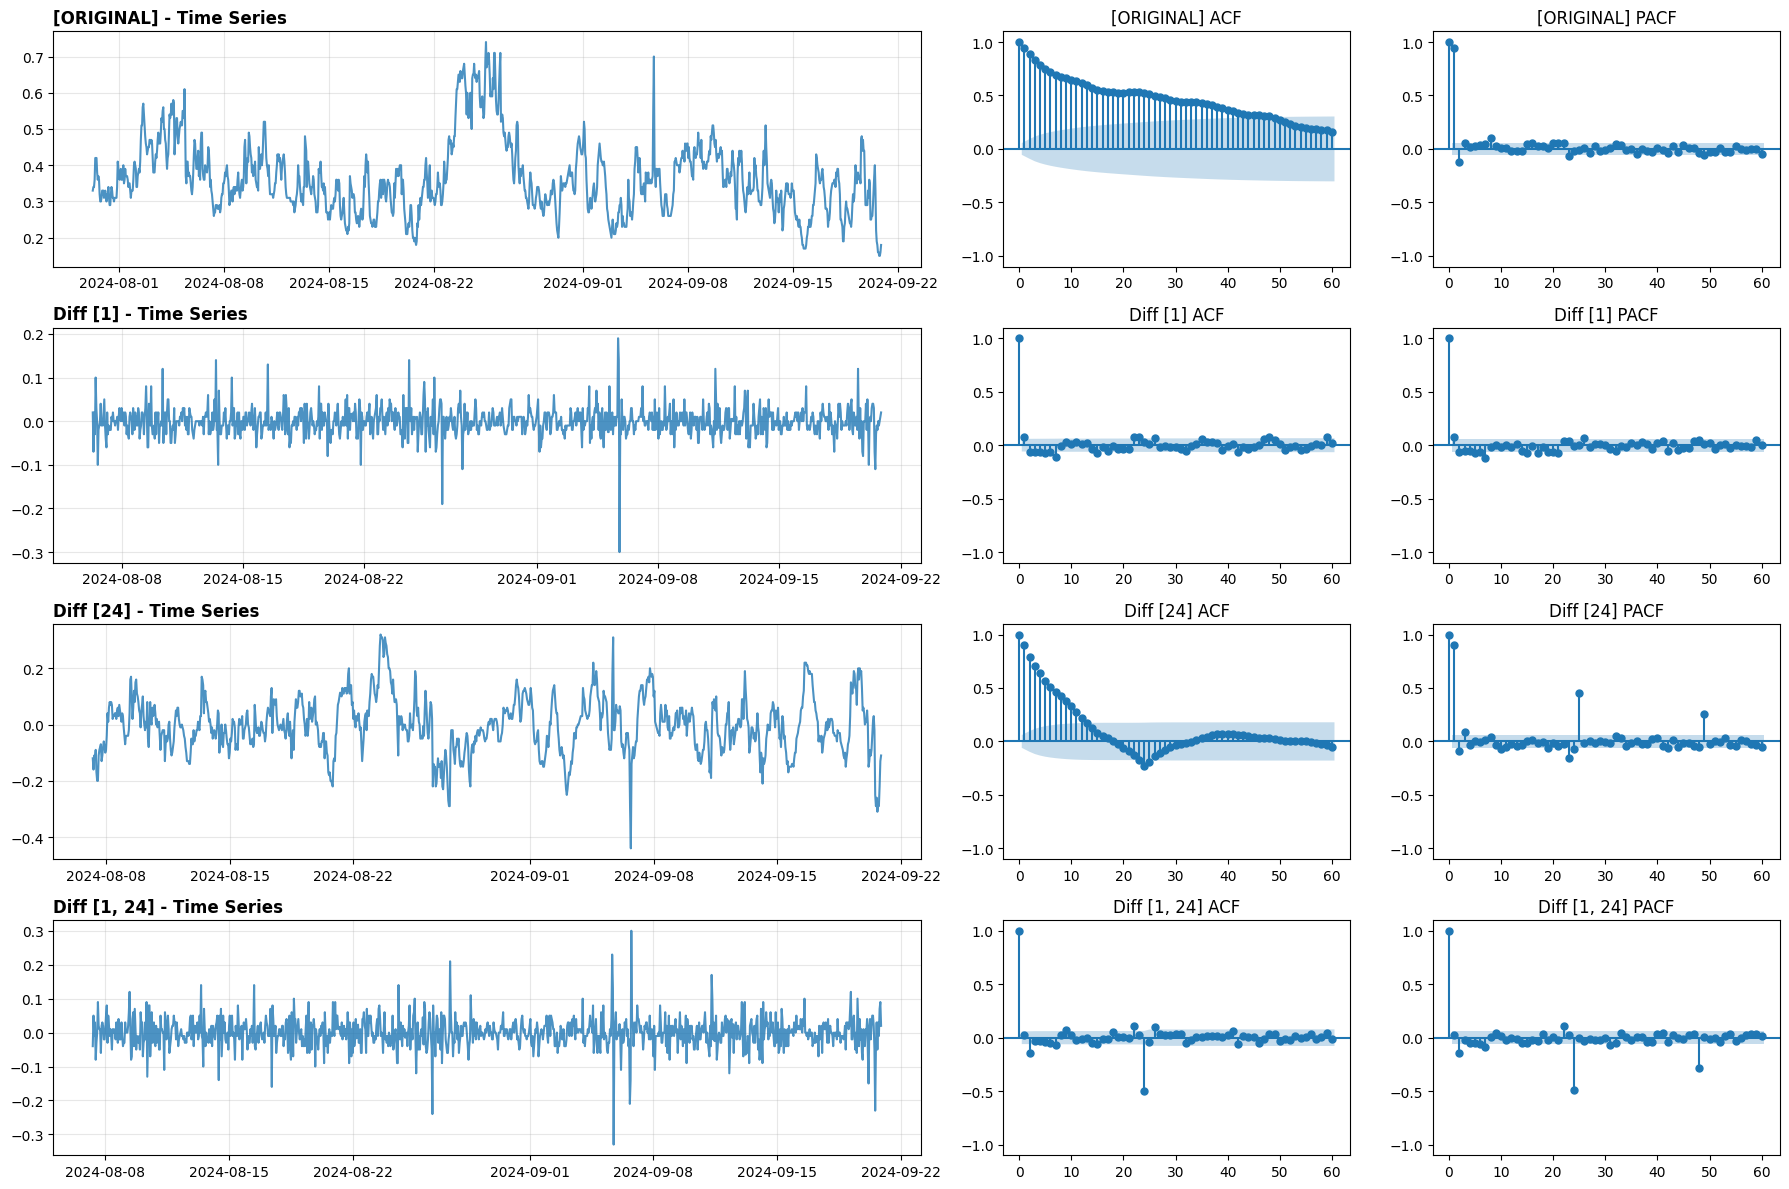

In [13]:
# ================================================================
# DIFFERENCING: REMOVE SEASONALITY (STATIONAR-IZE)

# GOAL : Getting a stationary time series
# HOW  : Apply several differences, plot the results and check the correlations with the lagged values
# WHY  : A stationary time series is easier to model (less noise, no trends/seasonality). The model can
#        focus on learning the patterns in the data, and the seasonality can be processed in other ways
#        (ex: seasonal features like hour of day, or fourrier terms). We want to avoid the model learning seasonality/patterns that are not
#        stable over time. We want low variance in the time series.

# ----------------------------------------------------------------
# METHOD: Check both the lower ADF value AND the correlation of the lagged values

# ADF TEST: We want to reach a low ADF statistic (below the critical values) with a low p-value (<0.05)
# If the ADF statistic is above the critical values, we are NOT stationary
# If the p-value is high (>0.05), we are probably NOT stationary

# CORRELATIONS of the target with the lagged values:
# If we have high POSITIVE correlation with lagged values, we are probably under-differencing 
# If we have high NEGATIVE correlation with lagged values, we are probably over-differencing
# We want to reach the sweet spot where the correlations are low (close to 0), with maybe a slight positive correlation (0-0.4)

# PLOTS (Y): We want to see an "horizontal" line without significant spikes/waves, trends or seasonality.
# The width of the spikes/waves should be small from left to right (low variance)

# ACF (Y): We want to see a quick drop-off of the ACF values, without significant spikes/waves.
# -> UNDER-DIFFERENCING if we see a very slow decay or significant spikes/waves in the ACF plot.
# -> OVER-DIFFERENCING if we see a NEGATIVE first bars (Lag 1, Lag 2...) in the ACF plot.
# -> GOOD if we see a LARGE spike for Lag 1, and then a quick drop-off to 0 (or slight negative, -0.1, -0.2)
#    for the other lags. To deal with the slight negative values for the first few lags, we can add some MA terms
#    in the model: MA(1) for Lag 1, MA(24) for Lag 24...

# PACF (Y): We use the PACF to decide how many lags to include in the model (AR terms).

# ----------------------------------------------------------------

# tsu.plot_differences_v2(rd_train_ts, differences=[[1], [24], [1, 24]])
tsu.get_differences_analysis(
    rd_train_ts, differences=[[1], [24], [1, 24]],
    # target_scaler=LocalStandardScaler()
)

DIFFERENCES = Differences([1])

In [14]:
# ================================================================
# SCALING: HARMONIZING THE VARIANCE BETWEEN SERIES

# GOAL : Harmonizing the variance between series
# HOW  : Apply a scaler on the target column after differencing
# WHY  : If you have multiple time series with different variances, the model
#        may focus too much on the high-variance series, so we scale the target.
#        This helps the model to learn patterns across all series more effectively.

# Scalers available in Nixtla:
# - LocalMinMaxScaler: Scales the target to a [0, 1] range based on the min and max values of each series.
# - LocalStandardScaler: Scales the target to have a mean of 0 and a standard deviation of 1 for each series.
# - LocalRobustScaler: Scales the target using the median and interquartile range, making it robust to outliers.

# ----------------------------------------------------------------

SCALER = LocalStandardScaler()
# SCALER = LocalRobustScaler(scale="mad")

In [15]:
# ================================================================
# LAGS: CAPTURING HISTORICAL PATTERNS (MEMORY)

# GOAL: Select the past time-steps that best predict the future target value.
# HOW : Identify significant spikes in the PACF plot and analyze the "Top Correlations" table.
# WHY : The differencing analysis helps us identify the lags that are most relevant for the model.
#       By adding these lag features, we provide the model with additional information that can help
#       it learn the patterns in the data better after differencing, and use them to create new
#       terms (AutoRegressive terms and Moving Averages). The lags should explain the residual patterns
#       that remain after differencing. LAGS CORRESPONDS TO THE AR TERMS.

# ----------------------------------------------------------------
# METHOD: Identify "Signals" vs. "Noise"
# PACF (Partial Autocorrelation): This is your primary tool for Lags.
# It shows the correlation between the target and a lag AFTER removing the influence of 
# intervening lags. The lags should explain what the differencing didn't already remove.
# -> SIGNIFICANT LAGS: Any bar that crosses the blue shaded area (confidence interval) is a 
#    potential candidate for a lag feature.
# -> THE "CUT-OFF": If PACF drops to zero after lag 'k', then 'k' is usually your maximum 
#    meaningful lag for that specific frequency.

# TOP CORRELATIONS (Absolute Value):
# -> HIGH CORRELATION (> 0.2): These are your "strong signals." Usually, Lag 1, 2, and 3 
#    are strong because the series has "momentum."
# -> SEASONAL LAGS: Look for spikes at your seasonal frequency (e.g., Lag 24 for hourly data, 
#    Lag 7 for daily data). Even if the correlation is lower than Lag 1, they are vital 
#    for capturing periodicity.

# CONSTRAINTS:
# -> Because we need as much past data as the maximum lag, we will lose the first N rows of each time series.
#    If use Lag 24, we can't predict the first 24 hours of each time series so we lose them.

# ----------------------------------------------------------------

LAGS = [1, 24]

In [16]:
# ================================================================
# LAG TRANSFORMS: SMOOTHING, MOMENTUM & WINDOW STATISTICS

# GOAL : Capture the "local behavior" (trends, volatility, averages) over time windows.
# HOW  : Apply RollingMean, SeasonalRollingMean, or ExpandingMean to the (differenced) series.
# WHY  : While "Lags" are specific points in time, "Transforms" provide the model with 
#        context. They help distinguish between a one-time spike and a sustained shift 
#        in level (noise reduction). LAG TRANSFORMS CORRESPONDS TO THE MA TERMS.

# ----------------------------------------------------------------
# RELATIONSHIP WITH CLASSICAL STATS (AR & MA)

# 1. LAGS <=> AR (Autoregressive) 
#    - Individual lags represent the AR component. 
#    - If PACF has sharp spikes, use Lags.

# 2. LAG TRANSFORMS <=> MA (Moving Average)
#    - In traditional models, MA terms use past forecast errors. In ML, we use 
#      Rolling Means of the target as a proxy.
#    - If ACF shows a "slow decay" or "persistent noise," a RollingMean helps 
#      the model understand the "average" state the series is trying to return to.

# ----------------------------------------------------------------
# METHOD: Choosing the right Transform during EDA

# ROLLING MEAN (e.g., window=7, 24):
# -> Use when: Your ACF shows high correlation over many consecutive lags.
# -> Effect: It smooths out high-frequency noise. If your Diff[1] series is very 
#    "jittery," a rolling mean helps the model see the underlying "local level."
# -> HIGH SPIKE AT LAG 1 then slightly positive/negative values: A Rolling Mean is better than a single Lag[1].

# SEASONAL ROLLING MEAN (e.g., season_length=24, window=7):
# -> Use when: You have strong seasonality, and the "value at 8:00 AM today" 
#    depends on the "average of 8:00 AM over the last 7 days."
# -> Check: Look at the ACF at seasonal multiples (24, 48, 72...). If those 
#    spikes are persistent, a Seasonal Rolling Mean is more powerful than a single Lag[24].
# -> HIGH RECCURRING SPIKES at SEASONAL LAGS: A Seasonal Rolling Mean is better than a single Lag[season_length].

# EXPANDING MEAN:
# -> Use when: The series has a long-term "drift" or the overall baseline is 
#    shifting slowly over the entire history. It provides a "global" reference point.

# ROLLING STD / ROLLING MAX:
# -> Use when: The "width" of the waves in your plot changes (Heteroscedasticity). 
#    This helps the model understand when the series is entering a "volatile" period.

# ----------------------------------------------------------------

LAG_TRANSFORMS = {
    1:  [RollingMean(window_size=7), RollingMean(window_size=24)], # Short-term & Daily momentum
    24: [SeasonalRollingMean(season_length=24, window_size=3)]    # window_size: 3 or 7
}

In [19]:
# ================================================================
# NIXTLA PIPELINE: CHECK ALL THE PREPROCESSING STEPS

DIFFERENCES = Differences([1])
SCALER = LocalStandardScaler()
LAGS = [1, 2, 24]
LAG_TRANSFORMS = {
    1:  [RollingMean(window_size=7), RollingMean(window_size=24)], # Short-term & Daily momentum
    24: [SeasonalRollingMean(season_length=24, window_size=3)]    # window_size: 3 or 7
}

# display(rd_train_ts.head(5))

fcst = MLForecast(
    models=[],  # just preprocessing
    freq="h",
    target_transforms=[
        DIFFERENCES,
        # SCALER
    ],
    lags=LAGS,
    lag_transforms=LAG_TRANSFORMS,
    date_features=["hour", "dayofweek"],
)
result = fcst.preprocess(rd_train_ts)

# Left Join with original 'y' values
result = result.merge(
    rd_train_ts[['unique_id', 'ds', 'y']], 
    on=['unique_id', 'ds'], 
    how='left', 
    suffixes=('', '_original') # This renames the original 'y' to 'y_original'
)


display(result.head(1))
print(result.shape)


,unique_id,ds,y,lag1,lag2,lag24,rolling_mean_lag1_window_size7,rolling_mean_lag1_window_size24,seasonal_rolling_mean_lag24_season_length24_window_size3,hour,dayofweek,y_original
0,2623191_S3,2024-08-02 07:00:00+00:00,0.01,0.03,0.0,0.02,0.001429,-0.000417,0.02,7,4,0.38


(1191, 12)


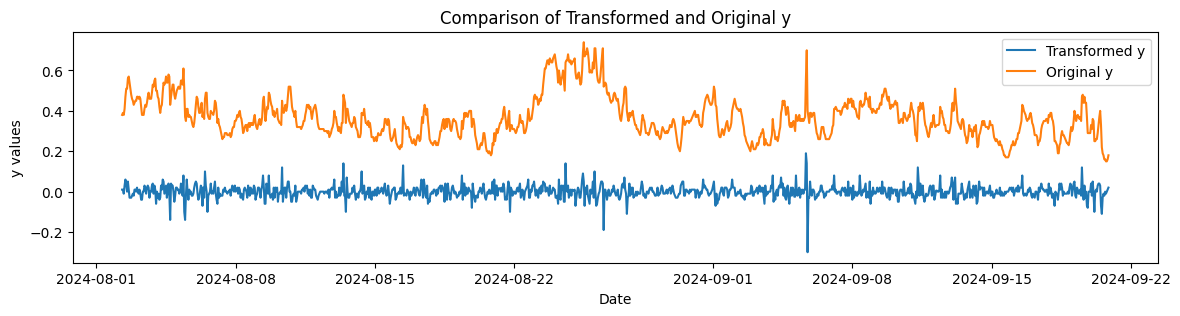

In [20]:
fig, ax = plt.subplots(figsize=(14, 3))

sns.lineplot(data=result, x="ds", y="y", label="Transformed y", ax=ax)
sns.lineplot(data=result, x="ds", y="y_original", label="Original y", ax=ax)
plt.title("Comparison of Transformed and Original y")
plt.xlabel("Date")
plt.ylabel("y values")
plt.legend()
plt.show()

#### Burn-in

In [22]:
# ================================================================
# MLForecast Burn-in Calculation

# PREPROCESSING STEPS
DIFFERENCES = Differences([1])
SCALER = LocalStandardScaler()
LAGS = [12, 24]
LAG_TRANSFORMS = {
    1: [
        RollingMean(window_size=7),
        RollingMean(window_size=24),
    ],  # Short-term & Daily momentum
    24: [SeasonalRollingMean(season_length=24, window_size=3)],  # window_size: 3 or 7
}

# CHECK BURN-IN
SEGMENT_SIZE = 336  # 14 days
burn_in = tsu.get_mlforecast_burn_in(
    segment_size=SEGMENT_SIZE,
    target_transforms=[DIFFERENCES],
    lags=LAGS,
    lag_transforms=LAG_TRANSFORMS,
)

MLForecast Burn-in Calculation
----------------------------------------------------------------
Rows lost (Burn-in): 96 (4.0 days)
Rows remaining for training: 240/336 (71.43%)



In [ ]:
# location_mask = train_df["location_id"] == "2622586"

# train_df[location_mask].tail(2)


KeyboardInterrupt



#### Optuna

In [14]:

from mlforecast.optimization import mlforecast_objective
from sklearn.metrics import root_mean_squared_error

# ================================================================
# OPTUNA GRID SEARCH

import warnings

# MLForecast warnings about the nulls in the exogenous features
warnings.filterwarnings("ignore", message="Found null values in")

# TARGET_COL = "pm25_ugm3"
# # TARGET_COL = "pm10_ugm3"
# # TARGET_COL = "no2_ppm"
# # TARGET_COL = "o3_ppm"
# # TARGET_COL = "so2_ppm"
# # TARGET_COL = "co_ppm"
# MODEL_NAME = "xgb_"+TARGET_COL

# # Apply weight penalty (>0.9 quantile) to high pollution events
# # QUANTILE: increase to focus on more extreme peaks. Decrease to include more values.
# # WEIGHTS: increase weights to better detect peaks. Reduce to lessen overpredictions.
# quantile_90 = train_df[TARGET_COL].quantile(0.95)
# def assign_weights(value):
#     return 6. if value > quantile_90 else 1.0
# train_df["y_weight_penalty"] = train_df[TARGET_COL].apply(assign_weights)

# train_ts = (
#     train_df.copy()
#     .rename(
#         columns={
#             "datetimeto_utc": "ds",
#             "segment_id": "unique_id",
#             TARGET_COL: "y",
#         }
#     )
#     .drop(columns=CustomXGBoostModel.get_other_pollutant_columns(TARGET_COL))
# )

# # ---------------------------------------------------------------------
# # MLForecast preprocessing setup

# LOG = []
# DIFFERENCES = []
# SCALER = [LocalStandardScaler()]  # kinda need this for a global model across all locations

# # For 504h segments (21 days)
# LAGS = [24, 48, 72, 168]
# LAG_TRANSFORMS = {
#     1: [
#         RollingMean(window_size=24, min_samples=1),  # 24h trend
#         RollingStd(window_size=24, min_samples=1),  # volatility
#         RollingMax(window_size=24, min_samples=1),  # peak detection
#     ],
#     24: [
#         SeasonalRollingMean(season_length=24, window_size=7, min_samples=1),
#     ],
#     168: [
#         RollingMean(window_size=1, min_samples=1),  # baseline weekly level
#     ],
# }

# STATIC_FEATURES = CustomXGBoostModel.STATIC_COLUMNS

TARGET_COL = "pm25_ugm3"
# TARGET_COL = "pm10_ugm3"
# TARGET_COL = "no2_ppm"
# TARGET_COL = "o3_ppm"
# TARGET_COL = "so2_ppm"
# TARGET_COL = "co_ppm"
MODEL_NAME = "xgb_" + TARGET_COL

train_ts = custom_xgb.prepare_timeseries_dataframe(train_df, TARGET_COL)

# ---------------------------------------------------------------------
# FIXED PARAMETERS

params = {
    "verbosity": 0,
    # LOWER learning rate + HIGHER estimators = More robust
    "n_estimators": 10000,
    # "n_estimators": 768,
    # 
    "learning_rate": 0.035,
    # Depth of each tree
    "max_depth": 6,
    # Stop the tree from splitting if the gain is too low (prevents overfitting)
    # 'gamma': 5,
    # Force the model to look at groups of data, not single outliers
    "min_child_weight": 10,
    # Add randomness to every tree build (prevents relying on one strong feature)
    "subsample": 0.6,
    "colsample_bytree": 0.3,
    # Regularization (Dampen sensitivity to noise)
    "reg_alpha": 11,  # L1
    "reg_lambda": 8,  # L2
}


def objective(trial) -> float:
    # ---------------------------------------------------------------------
    # SEARCH SPACE

    search_space = {
        # LOWER learning rate + HIGHER estimators = More robust
        "n_estimators": trial.suggest_int("n_estimators", 500, 2000, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.05),  # slow LR
        
        # Depth of each tree
        "max_depth": trial.suggest_int("max_depth", 3, 5),
        
        # Stop the tree from splitting if the gain is too low (prevents overfitting)
        'gamma': trial.suggest_float('gamma', 1.0, 10.0),
        
        "min_child_weight": trial.suggest_int('min_child_weight', 50, 150),
        # Add randomness to every tree build
        "subsample": trial.suggest_float("subsample", 0.3, 0.7),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.2, 0.5),
        
        # Regularization
        "reg_alpha": trial.suggest_float("reg_alpha", 5.0, 20.0),  # L1
        "reg_lambda": trial.suggest_float("reg_lambda", 5.0, 20.0),  # L2
    }

    # ---------------------------------------------------------------------
    # RUN THE CROSS VALIDATION

    final_params = {**params, **search_space}
    fcst = custom_xgb.create_mlforecaster(
        train_ts, TARGET_COL, final_params, debug=False
    )

    # reduce n_windows for speed during grid search
    prediction_setup = {"h": 72, "n_windows": 3, "step_size": 24}
    # prediction_setup = {"h": 72, "n_windows": 4, "step_size": 24}
    cv_res = fcst.cross_validation(
        train_ts,
        h=prediction_setup["h"],
        n_windows=prediction_setup["n_windows"],
        step_size=prediction_setup["step_size"],
        static_features=CustomXGBoostModel.STATIC_COLUMNS,
        # weight_col='y_weight_penalty',
        refit=False,  # for speed during grid search
        fitted=True,
    )

    # This returns a DataFrame of what the model predicted for the history it trained on
    train_preds = fcst.cross_validation_fitted_values()
    train_eval_df = evaluate(train_preds, metrics=[rmse])
    valid_eval_df = evaluate(cv_res.drop(columns="cutoff"), metrics=[rmse])

    # display(valid_eval_df.head())

    train_rmse = train_eval_df[MODEL_NAME].mean()
    valid_rmse = valid_eval_df[MODEL_NAME].mean()
    overfit_ratio = valid_rmse / train_rmse
    print(f"-> Trial {trial.number} - Overfit Ratio: {overfit_ratio:.3f}")

    # Add an overfitting penalty to the score
    threshold = 1.15
    overfit_penalty = (overfit_ratio - threshold) * 100 if overfit_ratio > threshold else 0
        
    trial.set_user_attr("train_rmse", train_rmse)
    trial.set_user_attr("valid_rmse", valid_rmse)

    # ---------------------------------------------------------------------
    # DEFINE THE OPTIMIZATION METRIC
    # Return the metric we want to MINIMIZE

    # # [Global RMSE] =======================================================
    # eval_df = evaluate(cv_res, metrics=[rmse])
    # score = eval_df[eval_df["metric"] == "rmse"]["xgb"].mean()

    # # [Custom Peak RMSE]  =================================================
    # peak_threshold = cv_res["y"].quantile(0.90)
    # peak_df = cv_res[cv_res["y"] > peak_threshold]
    # if len(peak_df) == 0:
    #     # Fallback if no peaks found (rare)
    #     score = root_mean_squared_error(cv_res["y"], cv_res["xgb"])
    # else:
    #     # Calculate RMSE specifically on the peaks
    #     score = root_mean_squared_error(peak_df["y"], peak_df["xgb"])

    # Optional: add stability penalty

    # [Custom Stability RMSE]  ===========================================

    # Calculate RMSE for each unique_id
    rmse_per_id = cv_res.groupby("unique_id")[["y", MODEL_NAME]].apply(
        lambda x: root_mean_squared_error(x["y"], x[MODEL_NAME]),
    )
    stability_mean = rmse_per_id.mean()
    stability_std = rmse_per_id.std()
        
    # THE FORMULA: Score = Mean Error + (Penalty_Factor * Stability)
    # If the model is unstable (high std), the score gets worse (higher).
    # Alpha of 1.0 means we care equally about accuracy and stability.
    score = stability_mean + (0.3 * stability_std) + overfit_penalty

    # Store these for analysis later
    trial.set_user_attr("stability_mean", stability_mean)
    trial.set_user_attr("stability_std", stability_std)

    # CLEANUP GPU MEMORY BETWEEN TRIALS
    del fcst, cv_res
    gc.collect()

    return score


# Create a study object
study = optuna.create_study(direction="minimize")
study.optimize(objective, n_trials=20)

print("Best Score:", study.best_value)
print("Best Params:", study.best_params)

# Convert all trials to a dataframe to analyze
trials_df = study.trials_dataframe().sort_values("value")

# Calculate Ratio manually (assuming you saved train_rmse as a user_attr)
trials_df['overfit_ratio'] = trials_df['user_attrs_valid_rmse'] / trials_df['user_attrs_train_rmse']

# The Selection Logic:
# "Give me the best model that ISN'T cheating"
best_model = trials_df[
    (trials_df['overfit_ratio'] < 1.15) &  # Strict guardrail
    (trials_df['overfit_ratio'] > 0.90)    # Sanity check (valid shouldn't be much better than train)
].sort_values('value')   # Sort by your main objective (RMSE)

# Show the results that didn't overfit
display(trials_df.sort_values('overfit_ratio', ascending=True).head(5))

[I 2026-01-06 09:57:29,611] A new study created in memory with name: no-name-89776700-3e23-40b0-b01c-44829d361675


-> Trial 0 - Overfit Ratio: 1.912


[I 2026-01-06 09:58:08,181] Trial 0 finished with value: 85.16096973055032 and parameters: {'n_estimators': 500, 'learning_rate': 0.03468902333110769, 'max_depth': 5, 'gamma': 3.0410873275118555, 'min_child_weight': 123, 'subsample': 0.5340652654794771, 'colsample_bytree': 0.4352862577510906, 'reg_alpha': 14.912861277555338, 'reg_lambda': 13.063932565896868}. Best is trial 0 with value: 85.16096973055032.


-> Trial 1 - Overfit Ratio: 1.786


[I 2026-01-06 09:58:47,298] Trial 1 finished with value: 72.06695841785262 and parameters: {'n_estimators': 500, 'learning_rate': 0.04544201008490225, 'max_depth': 5, 'gamma': 3.614741386027421, 'min_child_weight': 143, 'subsample': 0.4620109347178514, 'colsample_bytree': 0.23168685594298352, 'reg_alpha': 5.530913512084307, 'reg_lambda': 7.243278403145343}. Best is trial 1 with value: 72.06695841785262.


-> Trial 2 - Overfit Ratio: 1.903


... (33 outputs left out)

-> Trial 19 - Overfit Ratio: 1.822


[I 2026-01-06 10:12:04,586] Trial 19 finished with value: 75.18891579101921 and parameters: {'n_estimators': 1500, 'learning_rate': 0.030626380641275958, 'max_depth': 5, 'gamma': 4.129367410750415, 'min_child_weight': 55, 'subsample': 0.41245777852725285, 'colsample_bytree': 0.4010682231585362, 'reg_alpha': 19.343306877179995, 'reg_lambda': 16.32986050544642}. Best is trial 16 with value: 69.3851663813344.


Best Score: 69.3851663813344
Best Params: {'n_estimators': 2000, 'learning_rate': 0.03556179697145142, 'max_depth': 5, 'gamma': 2.289330777415043, 'min_child_weight': 106, 'subsample': 0.30868388328409396, 'colsample_bytree': 0.49559683685651895, 'reg_alpha': 11.350641812218562, 'reg_lambda': 19.944262764273923}


,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_alpha,params_reg_lambda,params_subsample,user_attrs_stability_mean,user_attrs_stability_std,user_attrs_train_rmse,user_attrs_valid_rmse,state,overfit_ratio
16,16,69.385166,2026-01-06 10:08:51.743522,2026-01-06 10:09:40.345809,0 days 00:00:48.602287,0.495597,2.289331,0.035562,5,106,2000,11.350642,19.944263,0.308684,6.560327,3.292041,3.709811,6.560327,COMPLETE,1.768372
5,5,70.007250,2026-01-06 10:00:59.896605,2026-01-06 10:01:47.994333,0 days 00:00:48.097728,0.241670,2.704072,0.039788,5,118,1600,18.338122,17.537605,0.405717,6.682682,3.291751,3.768351,6.682682,COMPLETE,1.773370
1,1,72.066958,2026-01-06 09:58:08.182547,2026-01-06 09:58:47.298765,0 days 00:00:39.116218,0.231687,3.614741,0.045442,5,143,500,5.530914,7.243278,0.462011,7.343481,3.643424,4.110990,7.343481,COMPLETE,1.786305
13,13,71.610102,2026-01-06 10:06:34.154897,2026-01-06 10:07:20.054326,0 days 00:00:45.899429,0.205053,3.083160,0.034435,5,148,1700,5.704141,9.496766,0.385497,6.814652,3.462563,3.812250,6.814652,COMPLETE,1.787567
11,11,71.804992,2026-01-06 10:05:13.957122,2026-01-06 10:05:54.833830,0 days 00:00:40.876708,0.201955,3.356603,0.047219,5,144,1000,5.106510,8.729466,0.367043,6.951060,3.493707,3.887491,6.951060,COMPLETE,1.788058


In [13]:
trials_df = study.trials_dataframe().sort_values("value")

In [14]:
trials_df.head()

,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_learning_rate,params_max_depth,params_min_child_weight,params_reg_alpha,user_attrs_stability_mean,user_attrs_stability_std,user_attrs_train_rmse,user_attrs_valid_rmse,state
11,11,7.680261,2026-01-06 02:22:20.009977,2026-01-06 02:23:01.599387,0 days 00:00:41.589410,0.300708,0.035255,6,10,11.173004,6.698545,3.272386,3.792819,6.698545,COMPLETE
9,9,7.693060,2026-01-06 02:20:59.088251,2026-01-06 02:21:40.144595,0 days 00:00:41.056344,0.347563,0.041433,6,10,12.752738,6.705990,3.290236,3.746455,6.705990,COMPLETE
10,10,7.722474,2026-01-06 02:21:40.145392,2026-01-06 02:22:20.009231,0 days 00:00:39.863839,0.303613,0.035508,6,10,11.353681,6.731935,3.301798,3.792176,6.731935,COMPLETE
13,13,7.732271,2026-01-06 02:23:42.561359,2026-01-06 02:24:22.001052,0 days 00:00:39.439693,0.548955,0.049489,6,10,11.943291,6.679436,3.509450,3.680819,6.679436,COMPLETE
12,12,7.747803,2026-01-06 02:23:01.600448,2026-01-06 02:23:42.560661,0 days 00:00:40.960213,0.314732,0.036599,6,10,10.761246,6.746408,3.337985,3.780157,6.746408,COMPLETE


In [15]:
# 3. Calculate Ratio manually (assuming you saved train_rmse as a user_attr)
trials_df['overfit_ratio'] = trials_df['user_attrs_valid_rmse'] / trials_df['user_attrs_train_rmse']

# 4. The Selection Logic:
# "Give me the best model that ISN'T cheating"
best_model = trials_df[
    (trials_df['overfit_ratio'] < 1.15) &  # Strict guardrail
    (trials_df['overfit_ratio'] > 0.90)    # Sanity check (valid shouldn't be much better than train)
].sort_values('value')   # Sort by your main objective (RMSE)

display(trials_df.sort_values('overfit_ratio', ascending=True).head(5))

,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_learning_rate,params_max_depth,params_min_child_weight,params_reg_alpha,user_attrs_stability_mean,user_attrs_stability_std,user_attrs_train_rmse,user_attrs_valid_rmse,state,overfit_ratio
11,11,7.680261,2026-01-06 02:22:20.009977,2026-01-06 02:23:01.599387,0 days 00:00:41.589410,0.300708,0.035255,6,10,11.173004,6.698545,3.272386,3.792819,6.698545,COMPLETE,1.766113
10,10,7.722474,2026-01-06 02:21:40.145392,2026-01-06 02:22:20.009231,0 days 00:00:39.863839,0.303613,0.035508,6,10,11.353681,6.731935,3.301798,3.792176,6.731935,COMPLETE,1.775217
12,12,7.747803,2026-01-06 02:23:01.600448,2026-01-06 02:23:42.560661,0 days 00:00:40.960213,0.314732,0.036599,6,10,10.761246,6.746408,3.337985,3.780157,6.746408,COMPLETE,1.784690
9,9,7.693060,2026-01-06 02:20:59.088251,2026-01-06 02:21:40.144595,0 days 00:00:41.056344,0.347563,0.041433,6,10,12.752738,6.705990,3.290236,3.746455,6.705990,COMPLETE,1.789956
8,8,7.814963,2026-01-06 02:20:18.046311,2026-01-06 02:20:59.087515,0 days 00:00:41.041204,0.360928,0.033997,6,12,9.374809,6.816896,3.326889,3.792550,6.816896,COMPLETE,1.797444


In [ ]:
# from mlforecast.optimization import mlforecast_objective
# from utilsforecast.losses import rmse

# # 1. Define a config function that tells Optuna WHAT to tune
# def config_fn(trial):
#     return {
#         "model_params": {
#             "n_estimators": trial.suggest_int("n_estimators", 300, 600),
#             "learning_rate": trial.suggest_float("learning_rate", 0.1, 0.3, log=True),
#             "max_depth": trial.suggest_int("max_depth", 10, 16),
#             "subsample": trial.suggest_float("subsample", 0.6, 1.0),
#             "tree_method": "hist",
#             "device": "cuda",
#         },
#         "mlf_init_params": {
#             "lags": LAGS,
#             "lag_transforms": LAG_TRANSFORMS,
#             "target_transforms": [SCALER],
#         },
#         "mlf_fit_params": {
#             "static_features": STATIC_FEATURES,
#         }
#     }

# # 2. Create the objective using the built-in Nixtla helper
# # This function automatically calls trial.report() and trial.should_prune() 
# # after each cross-validation window.
# objective = mlforecast_objective(
#     df=train_ts,
#     config_fn=config_fn,
#     loss=rmse,
#     model=XGBRegressor(), # Pass the base class here
#     freq="h",
#     n_windows=3,
#     h=24,
#     step_size=24,
#     refit=False,
# )

# # 3. Optimize as usual
# study = optuna.create_study(direction="minimize", pruner=optuna.pruners.MedianPruner())
# study.optimize(objective, n_trials=20)

In [ ]:
# Best Score: 6.830252041615132
# Best Params: {'n_estimators': 334, 'learning_rate': 0.05881132925986201, 'max_depth': 10, 'subsample': 0.7474851045601975}

# Best Score: 5.786108448288493
# Best Params: {'n_estimators': 441, 'learning_rate': 0.18118585668338338, 'max_depth': 10, 'subsample': 0.8610061591784797}

# refit=False
# Best Score: 5.5623188453972885
# Best Params: {'n_estimators': 568, 'learning_rate': 0.10088349566150312, 'max_depth': 14, 'subsample': 0.8567592274007878}

In [15]:
import optuna.visualization as vis

# 1. Optimization History: Check if the score is still improving
# If the line is still sharply declining, you need more trials.
vis.plot_optimization_history(study).show()

# 2. Parallel Coordinate Plot: Visualize the relationship between params and target
# This shows the "paths" that led to the best (lowest) RMSE.
vis.plot_parallel_coordinate(study).show()

# 3. Hyperparameter Importances: Which parameter actually moved the needle?
# Often you'll find 'learning_rate' or 'max_depth' do 90% of the work.
vis.plot_param_importances(study).show()

# 4. Slice Plot: View the distribution of each parameter
# Helps identify if the "best" value is hugging the edge of your search space.
vis.plot_slice(study).show()

In [17]:
vis.plot_contour(study, params=['learning_rate', 'max_depth']).show()

--- Top 5 Trials ---
       value  params_colsample_bytree  params_learning_rate  params_max_depth  params_min_child_weight  params_reg_alpha
23  6.611698                 0.343862              0.059529                 8                        9         11.270220
25  6.714874                 0.328035              0.059744                 8                        9         10.901539
28  6.744734                 0.349269              0.055171                 8                        5          7.609818
14  6.775231                 0.351557              0.050011                 8                        7          8.652491
18  6.782138                 0.409535              0.058708                 8                       10         11.774020

--- Parameter Correlation with RMSE ---
params_max_depth          -0.920075
duration                  -0.799762
params_learning_rate      -0.687006
number                    -0.611823
params_reg_alpha          -0.189969
params_colsample_bytree    0.331

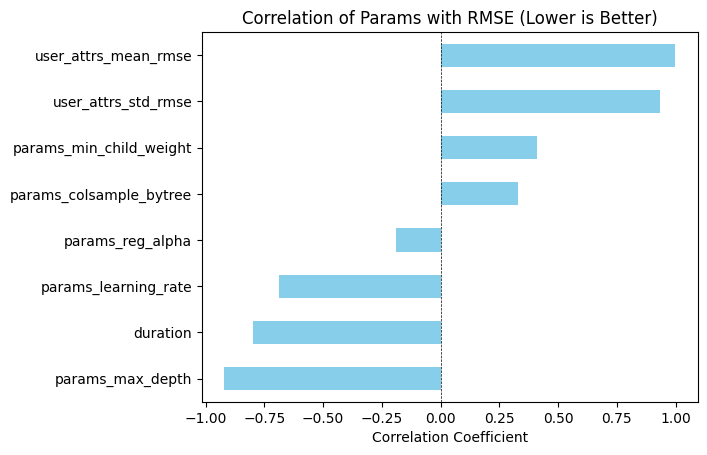

In [25]:
# ================================================================
# OPTUNA TRIALS ANALYSIS: HYPERPARAMETERS CORRELATIONS

# 1. Filter for only completed trials 
# (This removes failed trials or those interrupted)
completed_trials = trials_df[trials_df['state'] == 'COMPLETE'].copy()

# 2. Check top 5 trials 
# (Selecting only existing param columns to avoid errors if some are missing)
param_cols = [c for c in completed_trials.columns if c.startswith('params_')]
print("--- Top 5 Trials ---")
print(completed_trials[['value'] + param_cols].head(5))

# 3. Quick correlation check
# Use numeric_only=True to ignore the 'state' and 'datetime' columns
print("\n--- Parameter Correlation with RMSE ---")
correlations = completed_trials.select_dtypes(include=[np.number]).corr()['value'].sort_values()
print(correlations)

# SHOW A BAR CHART OF THE CORRELATIONS
# Drop the 'value' and 'number' columns so we only see params
param_corr = correlations.drop(labels=['value', 'number'], errors='ignore')

param_corr.plot(kind='barh', color='skyblue')
plt.title("Correlation of Params with RMSE (Lower is Better)")
plt.xlabel("Correlation Coefficient")
plt.axvline(0, color='black', linestyle='--', linewidth=0.5)
plt.show()

#### Features engineering

In [35]:
TARGET_COL = "pm25_ugm3"

train_ts = (
    train_df.copy()
    .rename(
        columns={
            "datetimeto_utc": "ds",
            "segment_id": "unique_id",
            TARGET_COL: "y",
        }
    )
    .drop(columns=CustomXGBoostModel.get_other_pollutant_columns(TARGET_COL))
)

XGB_HYPERPARAMS = {
    "tree_method": "hist",
    "device": "cuda",
    "n_estimators": 441,
    "learning_rate": 0.18118585668338338,
    "max_depth": 10,
    "subsample": 0.8610061591784797,
}


In [37]:
TARGET_COL = "pm25_ugm3"

DIFFERENCES = Differences([1])
SCALER = LocalStandardScaler()
# SCALER = LocalBoxCox()  # unstable, needs only positive values
# LAGS = [1, 2, 24]
LAGS = [1, 2, 12, 24]
LAG_TRANSFORMS = {
    1: [
        RollingMean(window_size=2),
        RollingMean(window_size=12),
        RollingMean(window_size=24),
    ],  # Short-term & Daily momentum
    12: [RollingMean(window_size=2)],  # Half-day momentum
    24: [SeasonalRollingMean(season_length=24, window_size=3)],  # window_size: 3 or 7
}
STATIC_FEATURES = CustomXGBoostModel.STATIC_COLUMNS

fcst = MLForecast(
    models={
        "naive": Naive(),
        "xgb": custom_xgb.create_xgb_model(train_ts, TARGET_COL, XGB_HYPERPARAMS),
        # 'q75': lgb.LGBMRegressor(**lgb_params, objective='quantile', alpha=0.75), # type: ignore
        # 'q25': lgb.LGBMRegressor(**lgb_params, objective='quantile', alpha=0.25), # type: ignore
    },
    freq="h",
    target_transforms=[DIFFERENCES, SCALER],
    # target_transforms=[SCALER],
    lags=LAGS,
    lag_transforms=LAG_TRANSFORMS,
)

In [38]:
prep = fcst.preprocess(train_ts, static_features=CustomXGBoostModel.STATIC_COLUMNS)
prep.head(1)

,location_id,ds,unique_id,segment_start,segment_end,segment_perfect_hours,segment_total_hours,segment_perfect_density,segment_tier,segments_num,segments_total,y,oaq_datetimeto_local,oaq_ismonitor,oaq_owner_id,oaq_provider_id,oaq_latitude,oaq_longitude,om_elevation,om_temperature_2m,om_relative_humidity_2m,om_dew_point_2m,om_precipitation,om_rain,om_snowfall,om_snow_depth,om_shortwave_radiation,om_direct_radiation,om_diffuse_radiation,om_weather_code,om_pressure_msl,om_cloud_cover,om_cloud_cover_low,om_cloud_cover_mid,om_cloud_cover_high,om_vapour_pressure_deficit,om_wind_speed_100m,om_wind_speed_10m,om_wind_direction_10m,om_wind_gusts_10m,om_is_day,feat_time__hour,feat_time__dow,feat_time__month,feat_time__hour_sin_k1,feat_time__hour_cos_k1,feat_time__hour_sin_k2,feat_time__hour_cos_k2,feat_time__hour_sin_k3,feat_time__hour_cos_k3,feat_time__dow_sin_k1,feat_time__dow_cos_k1,feat_time__month_sin_k1,feat_time__month_cos_k1,feat_time__is_rush_hour,feat_time__is_weekend,feat_time__is_party_night,feat_time__is_yellow_dust_season,feat_time__is_moonsoon_season,feat_time__is_winter_season,feat_time__is_summer_break,feat_time__is_winter_break,feat_time__is_spring_break,feat_time__is_school_break,feat_pollutant__expmean_pm25_ugm3,feat_pollutant__expmean_pm10_ugm3,feat_pollutant__expmean_no2_ppm,feat_pollutant__expmean_o3_ppm,feat_pollutant__expmean_so2_ppm,feat_pollutant__expmean_co_ppm,feat_pollutant__roll720_mean_pm25_ugm3,feat_pollutant__roll720_mean_pm10_ugm3,feat_pollutant__roll720_mean_no2_ppm,feat_pollutant__roll720_mean_o3_ppm,feat_pollutant__roll720_mean_so2_ppm,feat_pollutant__roll720_mean_co_ppm,feat_pollutant__lag168_pm25_ugm3,feat_pollutant__lag168_pm10_ugm3,feat_pollutant__lag168_no2_ppm,feat_pollutant__lag168_o3_ppm,feat_pollutant__lag168_so2_ppm,feat_pollutant__lag168_co_ppm,feat_pollutant__lag168_roll24_mean_pm25_ugm3,feat_pollutant__lag168_roll24_mean_pm10_ugm3,feat_pollutant__lag168_roll24_mean_no2_ppm,feat_pollutant__lag168_roll24_mean_o3_ppm,feat_pollutant__lag168_roll24_mean_so2_ppm,feat_pollutant__lag168_roll24_mean_co_ppm,feat_pollutant__lag168_roll24_stddev_pm25_ugm3,feat_pollutant__lag168_roll24_stddev_pm10_ugm3,feat_pollutant__lag168_roll24_stddev_no2_ppm,feat_pollutant__lag168_roll24_stddev_o3_ppm,feat_pollutant__lag168_roll24_stddev_so2_ppm,feat_pollutant__lag168_roll24_stddev_co_ppm,feat_pollutant__lag168_roll24_max_pm25_ugm3,feat_pollutant__lag168_roll24_max_pm10_ugm3,feat_pollutant__lag168_roll24_max_no2_ppm,feat_pollutant__lag168_roll24_max_o3_ppm,feat_pollutant__lag168_roll24_max_so2_ppm,feat_pollutant__lag168_roll24_max_co_ppm,feat_pollutant__lag168_pm25_pm10_index,feat_pollutant__lag168_no2_co_index,feat_weather__wind_direction_10m_sin,feat_weather__wind_direction_10m_cos,feat_weather__washout_index,feat_weather__moisture_trap_index,feat_weather__atmos_stability_index,feat_weather__moisture_saturation_index,feat_weather__dew_point_depression,feat_weather__photolytic_flux_index,feat_weather__wind_burst_ratio_index_10m,feat_weather__o3_potential_lag168,feat_weather__sulfate_potential_lag168,feat_weather__nitrate_potential_lag168,feat_weather__lag1_precipitation,feat_weather__delta1_pressure_msl,feat_weather__delta3_temperature_2m,pm25_ugm3_is_imputed,pm10_ugm3_is_imputed,no2_ppm_is_imputed,o3_ppm_is_imputed,so2_ppm_is_imputed,co_ppm_is_imputed,any_imputed,lag1,lag2,lag12,lag24,rolling_mean_lag1_window_size2,rolling_mean_lag1_window_size12,rolling_mean_lag1_window_size24,rolling_mean_lag12_window_size2,seasonal_rolling_mean_lag24_season_length24_window_size3
73,2622586,2024-05-03 16:00:00+00:00,2622586_S1,2024-04-30 15:00:00+00:00,2024-05-15 15:00:00+00:00,357,361,0.98892,gold,1,62,1.266084,2024-05-04 01:00:00,True,4,69,37.580167,127.044856,20.0,14.4,75,9.9,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,1018.2,0,0,0,0,0.42,5.0,4.2,59,4.7,0,1,5,4,0.258819,0.965926,0.5,0.866025,0.707107,0.707107,-0.974928,-0.222521,0.866025,-0.5,0,1,1,1,0,0,0,0,0,0,19.424658,37.315068,0.027892,0.04326,0.003105,0.437397,19.424658,37.315068,

In [ ]:
# # fcst = MLForecast(
# #     models={
# #         "naive": Naive(),
# #         "xgb": custom_xgb.create_xgb_model(train_ts, TARGET_COL, XGB_HYPERPARAMS),
# #         # 'q75': lgb.LGBMRegressor(**lgb_params, objective='quantile', alpha=0.75), # type: ignore
# #         # 'q25': lgb.LGBMRegressor(**lgb_params, objective='quantile', alpha=0.25), # type: ignore
# #     },
# #     freq="h",
# #     target_transforms=[DIFFERENCES, SCALER],
# #     # target_transforms=[SCALER],
# #     lags=LAGS,
# #     lag_transforms=LAG_TRANSFORMS,
# #     # date_features=["hour", "dayofweek"],
# #     # date_features=["hour", "dayofweek"],
# #     # date_features=[
# #     #     ("oaq_datetimeto_local", "hour"),
# #     #     ("oaq_datetimeto_local", "dayofweek"),
# #     # ],
# # )
# # # 
# # def debug_feature_names(fcst: MLForecast, train_df: pd.DataFrame) -> pd.DataFrame:
# #     """Preview feature names without fitting the actual XGBoost model."""

# #     # 1. Get the raw features produced by MLForecast (Lags, Windows, etc.)
# #     # This does NOT train the model, it just does the math for the lags.
# #     prep_df = fcst.preprocess(
# #         train_df, static_features=CustomXGBoostModel.STATIC_COLUMNS
# #     )

# #     X_raw = prep_df.drop(columns=["unique_id", "ds", "y"])

# #     # 2. Extract the 'skeleton' preprocessor from your model dictionary
# #     # Note: we use fcst.models['xgb'] (no underscore) to get the UNTRAINED object
# #     xgb_pipeline = fcst.models["xgb"]
# #     preprocessor = xgb_pipeline.named_steps["preprocessor"]

# #     # 3. Manually fit ONLY the preprocessor on the preprocessed data
# #     # We drop 'ds', 'unique_id', and 'y' because the preprocessor doesn't expect them
# #     # X_sample = prep_df.drop(columns=["ds", "unique_id", "y"])
# #     final_features = preprocessor.fit_transform(X_raw)

# #     # 4. Now you can get the names!
# #     feature_names = preprocessor.get_feature_names_out()

# #     final_df = pd.DataFrame(
# #         final_features,
# #         columns=feature_names,
# #         index=prep_df.index,  # Keep the original index for alignment # type: ignore
# #     ) # type: ignore
    
# #     print(f"Total Features: {len(feature_names)}")
# #     pprint(list(feature_names))
    
# #     return final_df

# # prep = debug_feature_names(fcst, train_ts)

# filter_columns = [col for col in prep.columns if col.startswith("date_")]
# mask_date = prep["date__debug_datetime"] > pd.to_datetime("2025-01-01 12:00:00")
# display(prep[filter_columns][mask_date].head(48))

In [ ]:
TARGET_COL = "pm25_ugm3"
# TARGET_COL = "co_ppm"

train_ts = (
    train_df.copy()
    .rename(
        columns={
            "datetimeto_utc": "ds",
            "segment_id": "unique_id",
            TARGET_COL: "y",
        }
    )
    .drop(columns=CustomXGBoostModel.get_other_pollutant_columns(TARGET_COL))
)

fcst = MLForecast(
    models={
        "naive": Naive(),
        "xgb": custom_xgb.create_xgb_model(train_ts, TARGET_COL, XGB_HYPERPARAMS),
    },
    freq="h",
    target_transforms=DIFFERENCES + SCALER,  # differencing removes too much # type: ignore
    # target_transforms=[SCALER],
    lags=LAGS,
    lag_transforms=LAG_TRANSFORMS,
)

# Features list (post preprocessing)
custom_xgb.print_feature_names(fcst, train_ts)

In [ ]:
# ================================================================
# FEATURE IMPORTANCE (FITTED MODEL)

# Access the model inside the pipeline
model = fcst.models_['xgb'].named_steps['model']
preprocessor = fcst.models_['xgb'].named_steps["preprocessor"]

importance = model.feature_importances_
names = preprocessor.get_feature_names_out()

# Sort and plot the top 20
feat_importances = pd.Series(importance, index=names)
feat_importances.nlargest(20).plot(kind='barh')
plt.show()

#### Cross-validating

In [36]:

# ================================================================
# CROSS-VALIDATION: EVALUATING MODEL ROBUSTNESS

# GOAL : Simulate multiple "deployments" to see how the model performs on unseen data.
#   h         : The forecast horizon (how many steps ahead we care about).
#   n_windows : How many separate test periods to create.

# ----------------------------------------------------------------
# HOW TO CHOOSE VALUES DURING EDA:

# 1. h (HORIZON):
#    Match this to your business requirement. If you need to plan staffing
#    for the next day, h=24. If you only care about the next hour, h=1.
#    -> Larger h makes the task harder (uncertainty accumulates).

# 2. n_windows:
#    - More windows = More statistical confidence in your error metric.
#    - Fewer windows = More training data available for each model.
#    -> For 14-day segments, keep n_windows low (2-4) to avoid "starving"
#       the first window of training data.

# ---------------------------------------------------------------------
# XGBoost hyperparameters

TARGET_COL = "pm25_ugm3"
# TARGET_COL = "pm10_ugm3"
# TARGET_COL = "no2_ppm"
# TARGET_COL = "o3_ppm"
# TARGET_COL = "so2_ppm"
# TARGET_COL = "co_ppm"
MODEL_NAME = "xgb_" + TARGET_COL

train_ts = custom_xgb.prepare_timeseries_dataframe(train_df, TARGET_COL)

fcst = custom_xgb.create_mlforecaster(train_ts, TARGET_COL)


# ================================================================
# CROSS-VALIDATION SETUP

# Minimum Training (before lags): Total_Length - h - ((n_windows-1) * step_size)

# Setup for 336h segments (14 days)
# prediction_setup = {"h": 24, "n_windows": 4, "step_size": 24}  # => 216h training (3/4 windows)
# prediction_setup = {"h": 24, "n_windows": 3, "step_size": 24}  # => 216h training (3/4 windows)
# prediction_setup = {"h": 72, "n_windows": 2, "step_size": 48}  # => 216h training
prediction_setup = {
    "h": 72,
    "n_windows": 3,
    "step_size": 24,
}  # => 216h training
# prediction_setup = {"h": 168, "n_windows": 1, "step_size": 168}  # => 168h training (stress test)

# Setup for 504h segments (21 days)
prediction_setup = {"h": 72, "n_windows": 4, "step_size": 24}

cv_result = fcst.cross_validation(
    train_ts,
    h=prediction_setup["h"],
    n_windows=prediction_setup["n_windows"],
    step_size=prediction_setup["step_size"],
    static_features=CustomXGBoostModel.STATIC_COLUMNS,
    # weight_col="y_weight_penalty",
    refit=True,
    fitted=True,
)
evaluation = tsu.print_cv_evaluation(MODEL_NAME, cv_result)


MLForecast Burn-in Calculation
----------------------------------------------------------------
Target Transform Cost: 0h
Max Lag Feature Cost: 192h
Total Rows Lost (Burn-in): 192h (8.0 days)
Rows remaining for training: 312h/504 (13.00 days)

Cross-Validation Report: [ 7.3434 ] RMSE (xgb_pm25_ugm3)
----------------------------------------------------------------
[RMSE]      :  7.3434 mean,  3.4973 std  |  47.63% (variance_%)  |   5.78% (error_range_%)
[PEAK_RMSE] : 17.7138 mean,  6.7113 std  |  37.89% (variance_%)  |  13.95% (error_range_%)
[MAE]       :  5.4336 mean,  2.5349 std  |  46.65% (variance_%)
[MAPE]      :  0.4234 mean,  0.2217 std  |  52.35% (variance_%)
----------------------------------------------------------------
STABILITY TRUTH CHECK (Normalized by Sensor Scale):
NRMSE Variance:      35.00%  <-- TRUST THIS NUMBER




In [24]:
# 2. Extract Training (In-Sample) Predictions
# This returns a DataFrame of what the model predicted for the history it trained on
train_preds = fcst.cross_validation_fitted_values()

# 1. Calculate Metrics (Don't manually rename yet to avoid guessing the column name)
train_error = evaluate(train_preds, metrics=[rmse])
valid_error = evaluate(cv_result.drop(columns='cutoff'), metrics=[rmse])

# 2. Merge with Suffixes
# This automatically renames colliding columns to 'rmse_train' and 'rmse_valid'
# (or 'root_mean_squared_error_train' if using sklearn metrics)
comparison = train_error.merge(
    valid_error, 
    on='unique_id', 
    suffixes=('_train', '_valid')
)
# 3. Identify the Metric Column Name Dynamically
# Find the column that ends with '_train' to know what the metric was named
metric_col_base = [c for c in comparison.columns if c.endswith('_train')][0].replace('_train', '')
# display(comparison.head(5))
# print(f"Detected metric column name: '{metric_col_base}'")

# 4. Calculate Ratio
comparison['overfit_ratio'] = (
    comparison[f'{MODEL_NAME}_valid'] / comparison[f'{MODEL_NAME}_train']
)


# 5. Display
print(f"Average overfit_ratio: {comparison['overfit_ratio'].mean():.3f} ({comparison[f'{MODEL_NAME}_valid'].mean():.3f} valid vs. {comparison[f'{MODEL_NAME}_train'].mean():.3f} train)")
print(comparison[[f'{MODEL_NAME}_train', f'{MODEL_NAME}_valid', 'overfit_ratio']].head())

Average overfit_ratio: 1.178 (6.446 valid vs. 5.499 train)
   xgb_pm25_ugm3_train  xgb_pm25_ugm3_valid  overfit_ratio
0             5.069115             6.978095       1.376590
1             4.342421             4.607749       1.061101
2             4.711801             5.002721       1.061743
3             5.239687             6.656260       1.270355
4             6.086510             4.697068       0.771718


Cross-Validation Report: [ 7.3434 ] RMSE (xgb_pm25_ugm3)
----------------------------------------------------------------
[RMSE]      :  7.3434 mean,  3.4973 std  |  47.63% (variance_%)  |   5.78% (error_range_%)
[PEAK_RMSE] : 17.7138 mean,  6.7113 std  |  37.89% (variance_%)  |  13.95% (error_range_%)
[MAE]       :  5.4336 mean,  2.5349 std  |  46.65% (variance_%)
[MAPE]      :  0.4234 mean,  0.2217 std  |  52.35% (variance_%)
----------------------------------------------------------------
STABILITY TRUTH CHECK (Normalized by Sensor Scale):
NRMSE Variance:      35.00%  <-- TRUST THIS NUMBER


Detailed Cross-Validation Evaluation
----------------------------------------------------------------


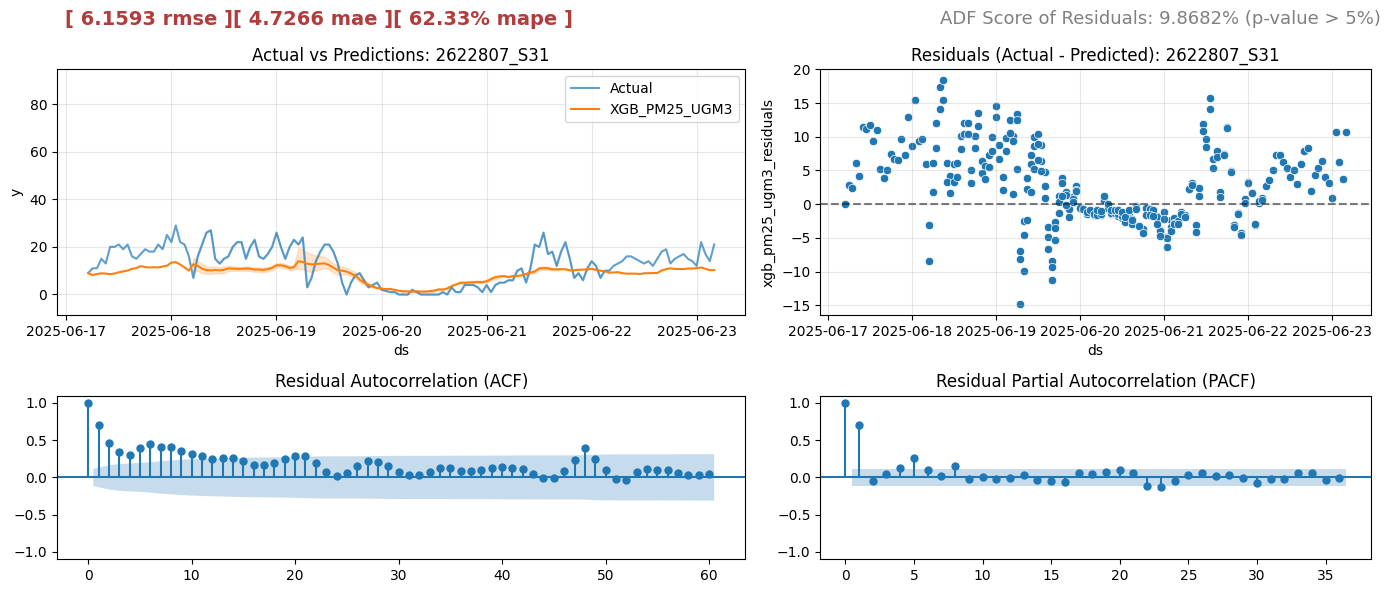

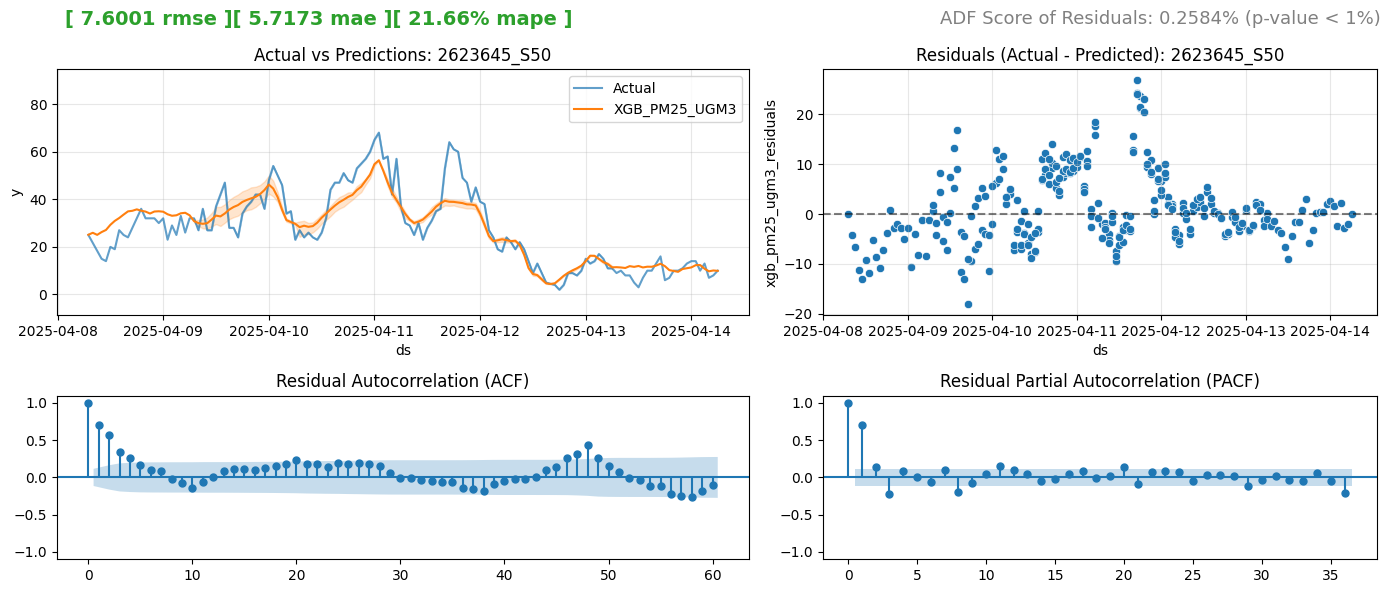

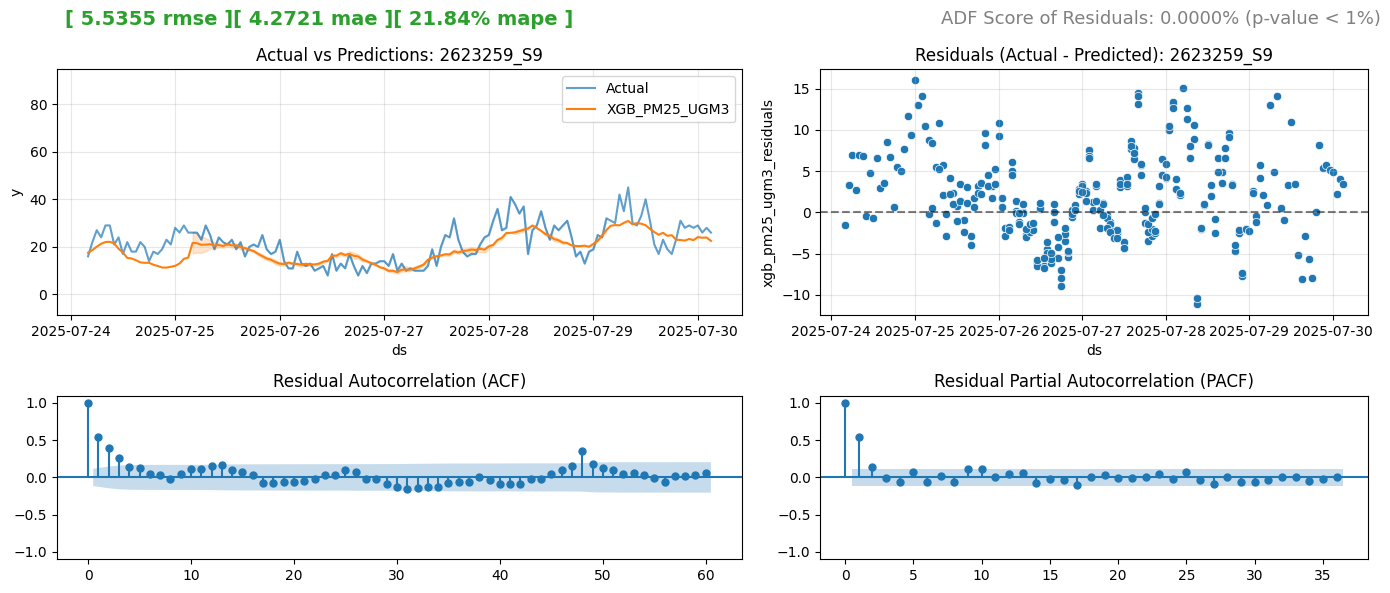

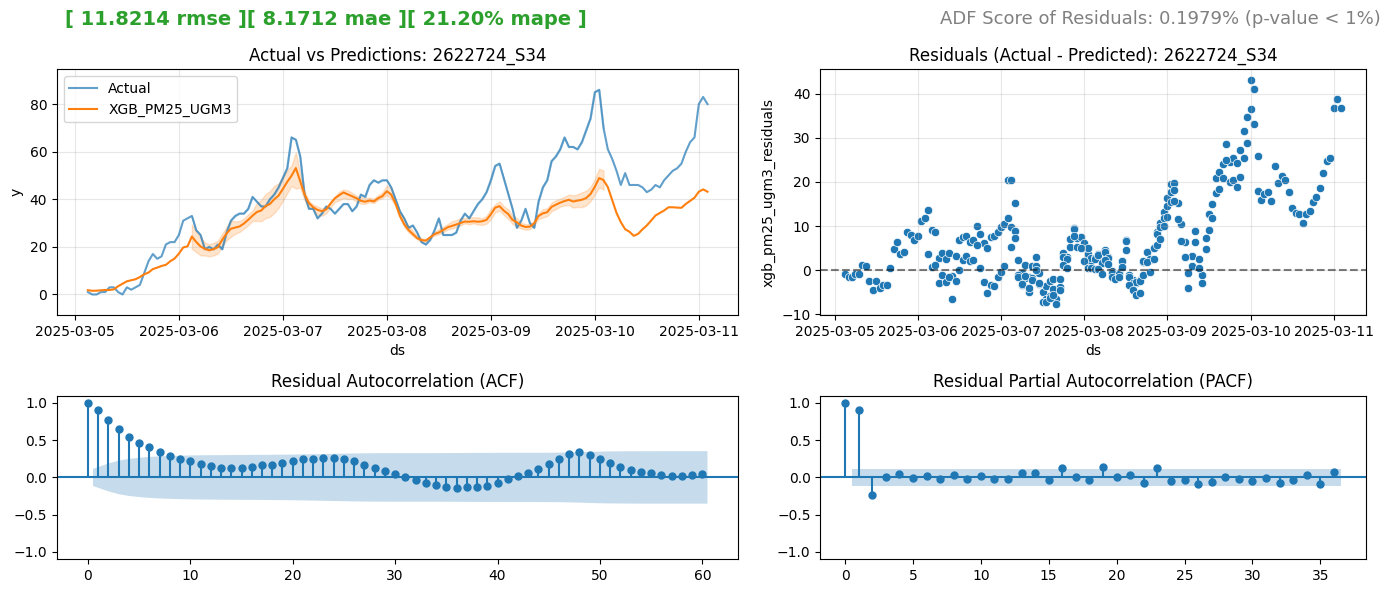

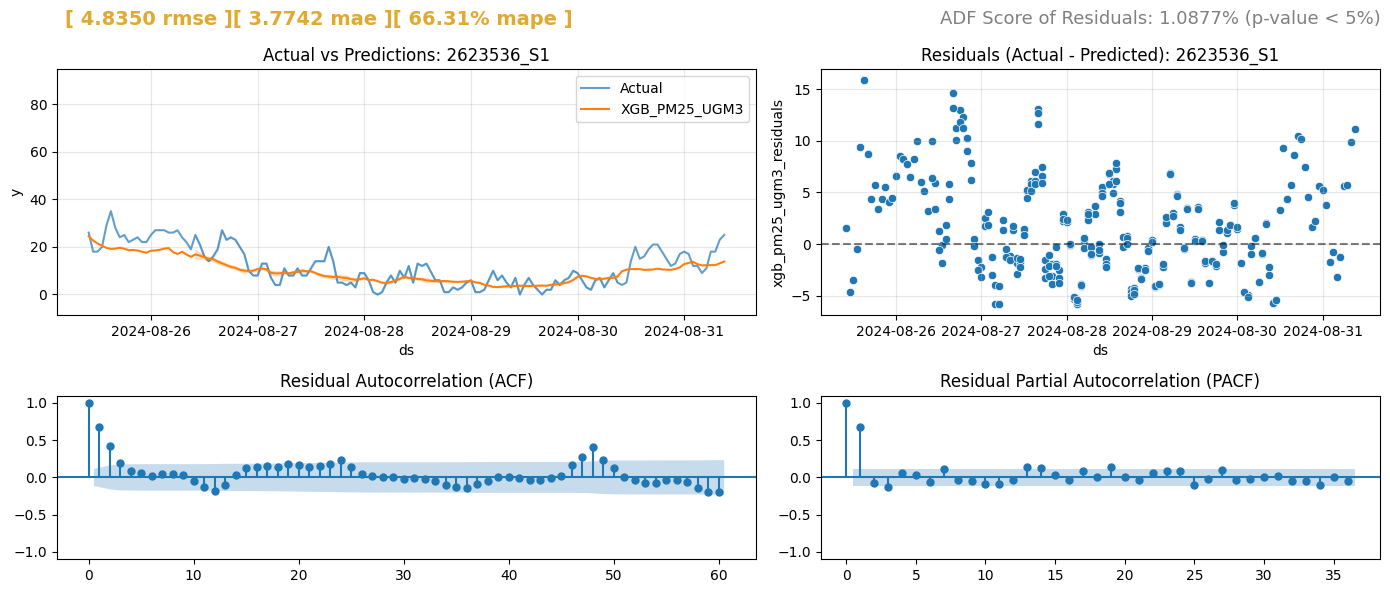

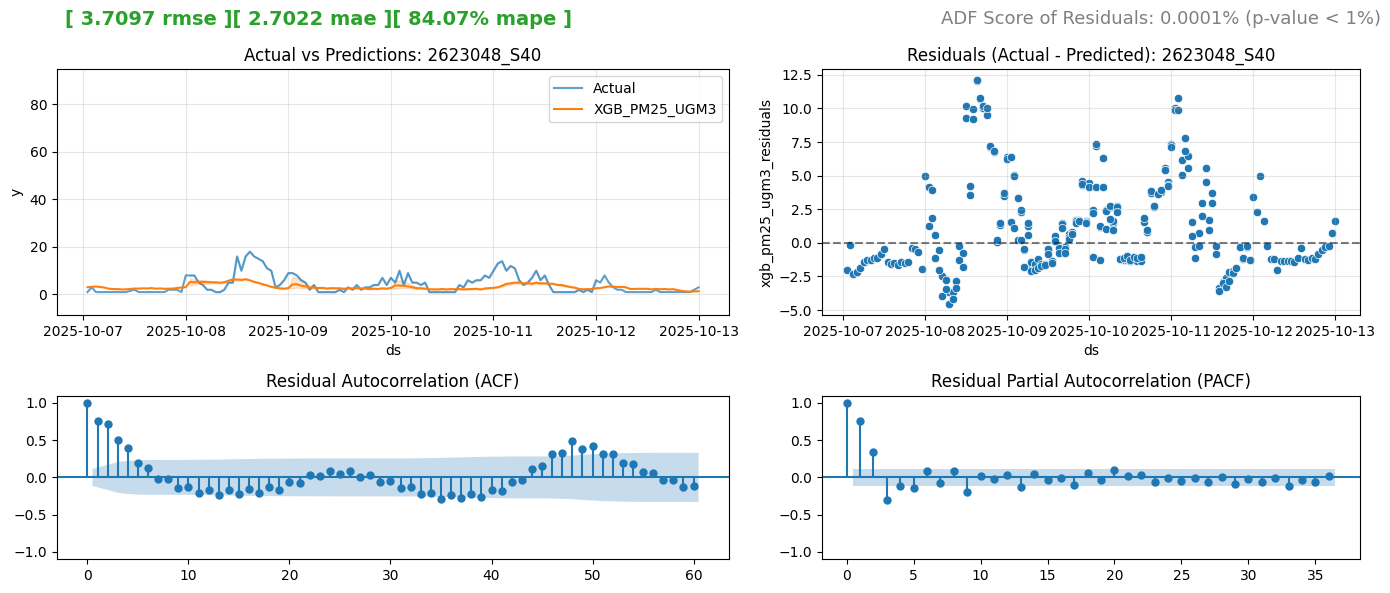

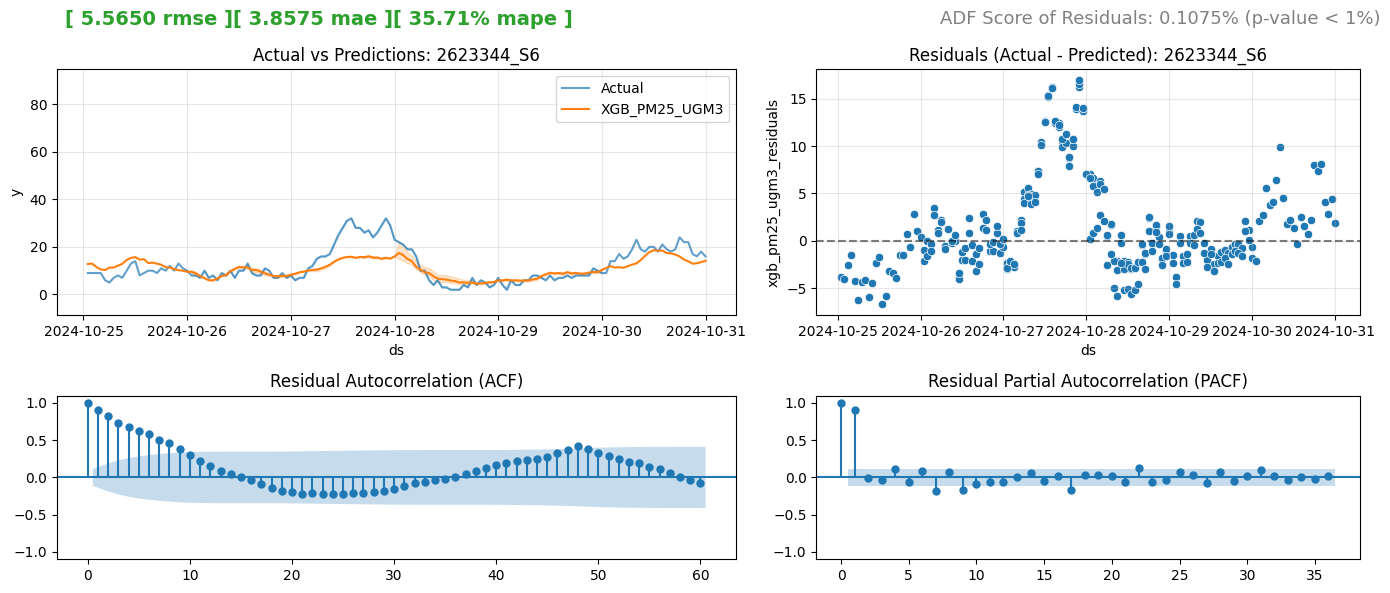

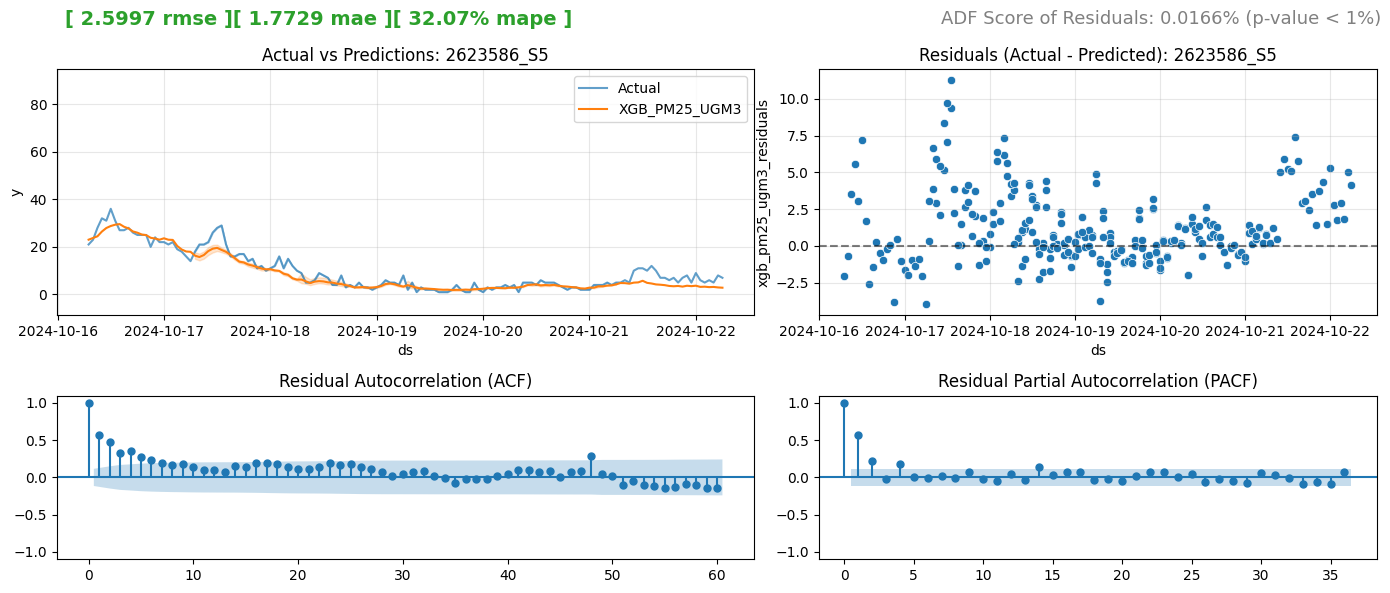

In [37]:
# ================================================================
# SPLIT THE EVALUATION PER UNIQUE_ID
cv_result[MODEL_NAME + "_residuals"] = cv_result["y"] - cv_result[MODEL_NAME]
# evaluation = tsu.print_cv_evaluation(MODEL_NAME, cv_result)
evaluation = tsu.print_cv_evaluation(MODEL_NAME, cv_result)
tsu.print_detailed_cv_evaluation(
    MODEL_NAME,
    cv_result,
    evaluation,
    show_adf=False,
    minmax_scaled=True,
    figsize=(14, 6),
    # random_state=69,
)

##### FIT & FEATURES IMPORTANCE

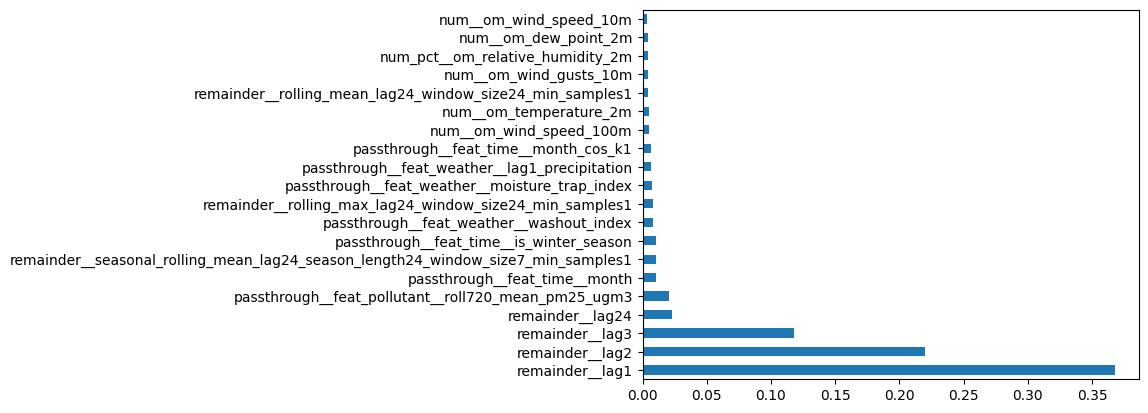

remainder__lag1                                                                     0.367912
remainder__lag2                                                                     0.220163
remainder__lag3                                                                     0.117909
remainder__lag24                                                                    0.023261
passthrough__feat_pollutant__roll720_mean_pm25_ugm3                                 0.020796
passthrough__feat_time__month                                                       0.010391
remainder__seasonal_rolling_mean_lag24_season_length24_window_size7_min_samples1    0.010378
passthrough__feat_time__is_winter_season                                            0.010122
passthrough__feat_weather__washout_index                                            0.007979
remainder__rolling_max_lag24_window_size24_min_samples1                             0.007909
passthrough__feat_weather__moisture_trap_index                        

In [38]:
# ================================================================
# FEATURE IMPORTANCE (FITTED MODEL)

fcst.fit(
    train_ts,
    static_features=CustomXGBoostModel.STATIC_COLUMNS,
    # weight_col="y_weight_penalty",
)

wrapper = fcst.models_[MODEL_NAME]

# # Access the model inside the pipeline
inner_pipeline = wrapper.pipeline
model = inner_pipeline.named_steps['model']
preprocessor = inner_pipeline.named_steps['preprocessor']

importance = model.feature_importances_
names = preprocessor.get_feature_names_out()

# Sort and plot the top 20
feat_importances = pd.Series(importance, index=names)
feat_importances.nlargest(20).plot(kind='barh')
plt.show()

display(feat_importances.nlargest(500))

In [125]:
# # TODO: Plot the validation metrics vs the train metrics to check for overfitting

# from utilsforecast.evaluation import evaluate
# from utilsforecast.losses import rmse, mae, mape

# # 1. Run cross-validation to get VALIDATION errors
# cv_result = fcst.cross_validation(
#     train_ts,
#     h=24,
#     n_windows=3,
#     step_size=24,
#     refit=True, # Critical: Model is retrained for each window
# )

# # 2. Get VALIDATION metrics (Unseen data)
# val_metrics = evaluate(cv_result, metrics=[rmse, mae, mape])

# # 3. To get TRAINING metrics (Seen data), you must manually fit on the train set
# # and predict the same training period. 
# # Note: In MLForecast, fit() trains on the whole train_ts.
# fcst.fit(train_ts)
# train_preds = fcst.predict_insample() # Predicts on the data it just saw

# # 4. Get TRAINING metrics
# train_metrics = evaluate(train_preds, metrics=[rmse, mae, mape])

# # """
# # Scenario | Diagnosis | Action
# # Train RMSE ≈ Val RMSE       | Good Fit      | No action needed.
# # Train RMSE ≪ Val RMSE       | Overfitting   | "Reduce max_depth, increase reg_lambda, or reduce features."
# # Train RMSE ≈ High Val RMSE  | Underfitting  | "Increase max_depth, add more features, or more n_estimators."
# # """

# # """
# # Test RMSE in each window of each serie: if the error has high variance this is a secondary sign of overfitting.
# # """

In [ ]:
# ================================================================
# EVALUATING PERFORMANCE ACROSS CV WINDOWS

# GOAL : Determine if model performance is stable or degrading across time splits.
# HOW  : Group the cross_validation results by the 'cutoff' column.
# WHY  : In your 14-day segments, early windows have very little training data 
#        (due to burn-in). Comparing errors window-by-window helps identify if 
#        you are "data-starved" in early splits.

# ----------------------------------------------------------------
# METHOD: The "Per-Window" Error Analysis

# 1. THE 'cutoff' COLUMN: 
#    - Each window is identified by its 'cutoff' (the date training ended).
#    - Window 0 is usually the earliest (least training data).
#    - Window N is the most recent (most training data).

# 2. EVALUATION METRIC:
#    - We use utilsforecast.evaluation to compute metrics (like RMSE) 
#      for each unique cutoff.

# ----------------------------------------------------------------
# WHAT TO WATCH OUT FOR:

# -> INCREASING ERROR IN EARLY WINDOWS: If Window 0 has much higher error 
#    than Window 3, your burn-in is likely too high. You don't have 
#    enough history left to train a stable model for the early splits.
# -> HIGH VARIANCE ACROSS WINDOWS: If errors fluctuate wildly, the series 
#    is likely non-stationary or has outliers that your current 
#    differencing/lags haven't stabilized.

# ----------------------------------------------------------------

from utilsforecast.evaluation import evaluate
from utilsforecast.losses import rmse, mae

# Compute metrics per window (cutoff)
window_errors = evaluate(
    cv_result,
    metrics=[rmse, mae],
    id_col='unique_id',
    time_col='ds',
    target_col='y'
)

# Note: cv_result contains a 'cutoff' column. To see errors per window:
cv_result.groupby('cutoff').apply(lambda df: evaluate(df, [rmse]))

In [ ]:
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import rmse

# This gives you a DF with columns: [unique_id, cutoff, model_name]
errors_per_window = evaluate(
    cv_result,
    metrics=[rmse],
)

# Sort by cutoff to see the chronological order of windows
errors_per_window = errors_per_window.sort_values('cutoff')

In [ ]:
import matplotlib.pyplot as plt

# Plotting the RMSE over time (cutoffs)
for uid in errors_per_window['unique_id'].unique():
    subset = errors_per_window[errors_per_window['unique_id'] == uid]
    plt.plot(subset['cutoff'], subset['xgb'], marker='o', label=uid)

plt.title("RMSE by CV Window (Cutoff)")
plt.xticks(rotation=45)
# plt.legend()
plt.show()

In [ ]:
# 1. Group by unique_id and calculate the standard deviation of the error
erratic_series = errors_per_window.groupby('unique_id')['xgb'].std().reset_index()
erratic_series.columns = ['unique_id', 'rmse_std']

# 2. Sort to find the top 5 most unstable
top_5_erratic = erratic_series.sort_values('rmse_std', ascending=False).head(5)

# 3. Filter the original CV results to plot only these 5
top_5_ids = top_5_erratic['unique_id'].tolist()
filtered_errors = errors_per_window[errors_per_window['unique_id'].isin(top_5_ids)]

print(top_5_ids)
print(filtered_errors)

In [ ]:
# Alternative evaluation function

from utilsforecast.losses import mae, mape, rmse, smape
from utilsforecast.evaluation import evaluate

metrics = [
    mae,
    rmse,
    mape,
    smape
]

# Function to evaluate the crossvalidation
def evaluate_crossvalidation(crossvalidation_df, metrics, models):
    evaluations = []
    for c in crossvalidation_df['cutoff'].unique():
        df_cv = crossvalidation_df.query('cutoff == @c')
        evaluation = evaluate(
            df = df_cv,
            metrics=metrics,
            models=list(models.keys())
            )
        evaluations.append(evaluation)
    evaluations = pd.concat(evaluations, ignore_index=True).drop(columns='unique_id')
    evaluations = evaluations.groupby('metric').mean()
    return evaluations.style.background_gradient(cmap='RdYlGn_r', axis=1)

In [ ]:
# Example from Nixtla

# levels = [90, 95] # Levels for prediction intervals
# preds_level = fcst.predict(24)
# preds_level.head(10)
preds = fcst.predict(24, )
preds.head(10)
plot_series(train_ts, preds, max_insample_length=24 * 7, seed=4223, max_ids=4, plot_random=True)

In [ ]:
# fig = plot_series(forecasts_df=cv_result.drop(columns=['cutoff', 'q25', 'q75']))
# display(fig)

### ***↪***&nbsp;&nbsp;**XGBoost - Big Training**

#### Train (once per pollutant)

In [7]:
# ================================================================
# LOAD THE ENTIRE DATASET (ALL LOCATIONS)

custom_xgb = CustomXGBoostModel()


# BigQuery
start_time = time.perf_counter()
query = """
    SELECT
        *
    FROM `openaq-anomaly-prediction.dev_serving.ml_seoul__xgb_features`
    WHERE datetimeto_utc <= '2025-10-31'
      AND segment_total_hours >= 504
    ORDER BY location_id, datetimeto_utc ASC
"""
query_parameters = [
    # ("dataset", "STRING", dataset)
]
train_df = bq.query(query, query_parameters=query_parameters, dry_run=False)
custom_xgb.categorize_columns(train_df)

# ================================================================
# INTERPOLATE ALL POLLUTANTS
 
train_df = custom_xgb.interpolate_pollutants(train_df, debug=True)
custom_xgb.print_nan_report(train_df)


# ================================================================
# COLUMNS CATEGORIZATION
 
display(train_df.head(5))
custom_xgb.print_categories_report()

INTERPOLATING 6 POLLUTANTS
----------------------------------------------------------------
BEFORE: 86755 total NaN values
    -> Adding columns       : ['pm25_ugm3_is_imputed', 'pm10_ugm3_is_imputed', 'no2_ppm_is_imputed', 'o3_ppm_is_imputed', 'so2_ppm_is_imputed', 'co_ppm_is_imputed', 'any_imputed']
    -> Grouped by           : ['location_id', 'segment_id']
    -> Linear interpolation : up to 4 hours
    -> Forward fill         : up to 4 hours
    -> Backward fill        : up to 4 hours
AFTER: 0 total NaN values

[ TARGET    ]: 0 NaN values in the target columns
[ OPENAQ    ]: 0 NaN values in OpenAQ columns
[ OPENMETEO ]: 0 NaN values in OpenMeteo columns
[ FEATURES  ]: 4304 NaN values in features columns
feat_weather__delta3_temperature_2m         2280
feat_weather__lag1_precipitation             760
feat_weather__delta1_pressure_msl            760
feat_pollutant__roll720_mean_so2_ppm          42
feat_pollutant__expmean_pm25_ugm3             42
feat_pollutant__expmean_no2_ppm      

,location_id,datetimeto_utc,concurrent_sensors,segment_id,segment_start,segment_end,segment_perfect_hours,segment_total_hours,segment_perfect_density,segment_tier,segments_num,segments_total,pm25_ugm3,pm10_ugm3,no2_ppm,o3_ppm,so2_ppm,co_ppm,oaq_datetimeto_local,oaq_ismonitor,oaq_owner_id,oaq_provider_id,oaq_latitude,oaq_longitude,om_elevation,om_temperature_2m,om_relative_humidity_2m,om_dew_point_2m,om_precipitation,om_rain,om_snowfall,om_snow_depth,om_shortwave_radiation,om_direct_radiation,om_diffuse_radiation,om_weather_code,om_pressure_msl,om_cloud_cover,om_cloud_cover_low,om_cloud_cover_mid,om_cloud_cover_high,om_vapour_pressure_deficit,om_wind_speed_100m,om_wind_speed_10m,om_wind_direction_10m,om_wind_gusts_10m,om_is_day,feat_time__hour,feat_time__dow,feat_time__month,feat_time__hour_sin_k1,feat_time__hour_cos_k1,feat_time__hour_sin_k2,feat_time__hour_cos_k2,feat_time__hour_sin_k3,feat_time__hour_cos_k3,feat_time__dow_sin_k1,feat_time__dow_cos_k1,feat_time__month_sin_k1,feat_time__month_cos_k1,feat_time__is_rush_hour,feat_time__is_weekend,feat_time__is_party_night,feat_time__is_yellow_dust_season,feat_time__is_moonsoon_season,feat_time__is_winter_season,feat_time__is_summer_break,feat_time__is_winter_break,feat_time__is_spring_break,feat_time__is_school_break,feat_pollutant__expmean_pm25_ugm3,feat_pollutant__expmean_pm10_ugm3,feat_pollutant__expmean_no2_ppm,feat_pollutant__expmean_o3_ppm,feat_pollutant__expmean_so2_ppm,feat_pollutant__expmean_co_ppm,feat_pollutant__roll720_mean_pm25_ugm3,feat_pollutant__roll720_mean_pm10_ugm3,feat_pollutant__roll720_mean_no2_ppm,feat_pollutant__roll720_mean_o3_ppm,feat_pollutant__roll720_mean_so2_ppm,feat_pollutant__roll720_mean_co_ppm,feat_weather__wind_direction_10m_sin,feat_weather__wind_direction_10m_cos,feat_weather__washout_index,feat_weather__moisture_trap_index,feat_weather__atmos_stability_index,feat_weather__moisture_saturation_index,feat_weather__dew_point_depression,feat_weather__photolytic_flux_index,feat_weather__wind_burst_ratio_index_10m,feat_weather__lag1_precipitation,feat_weather__delta1_pressure_msl,feat_weather__delta3_temperature_2m,pm25_ugm3_is_imputed,pm10_ugm3_is_imputed,no2_ppm_is_imputed,o3_ppm_is_imputed,so2_ppm_is_imputed,co_ppm_is_imputed,any_imputed
0,2622586,2024-05-16 01:00:00+00:00,6,2622586_S2,2024-05-16 01:00:00+00:00,2024-07-04 05:00:00+00:00,1137,1181,0.962743,gold,2,62,5.0,23.000000,0.0184,0.024800,0.002500,0.400000,2024-05-16 10:00:00,True,4,69,37.580167,127.044856,20.0,13.2,68,7.5,0.0,0.0,0.0,0.0,673.0,503.0,170.0,0,1011.3,0,0,0,0,0.49,13.3,10.5,301,22.3,1,10,3,4,5.000000e-01,-0.866025,-8.660254e-01,0.500000,1.000000e+00,1.194340e-15,0.433884,-0.900969,0.866025,-0.5,0,0,0,1,0,0,0,0,0,0,15.183844,32.509749,0.022980,0.040603,0.002923,0.401176,15.183844,32.509749,0.022980,0.040603,0.002923,0.401176,-0.857167,0.515038,0.0,6549.371429,96.314286,1.694915,5.7,64819.514286,2.123810,NaN,NaN,NaN,0,0,0,0,0,0,0
1,2622586,2024-05-16 02:00:00+00:00,6,2622586_S2,2024-05-16 01:00:00+00:00,2024-07-04 05:00:00+00:00,1137,1181,0.962743,gold,2,62,10.0,27.000000,0.0166,0.029300,0.003000,0.390000,2024-05-16 11:00:00,True,4,69,37.580167,127.044856,20.0,15.1,60,7.2,0.0,0.0,0.0,0.0,812.0,630.0,182.0,0,1010.6,0,0,0,0,0.69,14.1,11.3,301,23.8,1,11,3,4,2.588190e-01,-0.965926,-5.000000e-01,0.866025,7.071068e-01,-7.071068e-01,0.433884,-0.900969,0.866025,-0.5,0,0,0,1,0,0,0,0,0,0,15.155556,32.483333,0.022967,0.040559,0.002922,0.401173,15.155556,32.483333,0.022967,0.040559,0.002922,0.401173,-0.857167,0.515038,0.0,5366.017699,89.433628,1.265823,7.9,72620.106195,2.106195,0.0,-0.7,NaN,0,0,0,0,0,0,0
2,2622586,2024-05-16 03:00:00+00:00,0,2622586_S2,2024-05-16 01:00:00+00:00,2024-07-04 05:00:00+00:00,1137,1181,0.962743,gold,2,62,10.0,26.333333,0.0156,0.033833,0.002967,0.383333,2024-05-16 12:00:00,True,4,69,37.580167,127.044856,20.0,16.7,50,6.3,0.0,0.0,0.0,0.0,899.0,707.0,192.0,0,1009.8,0,0,0,0,0.94,17.3,13.6,292,26.6,1,12,3,4,1.224647e-16,-1.000000,-2.449294e-16,1.000000,3.673940e-16,-1

COLUMNS CATEGORIZATION

Pollutants columns (6):
['pm25_ugm3', 'pm10_ugm3', 'no2_ppm', 'o3_ppm', 'so2_ppm', 'co_ppm']

OpenAQ columns (6):
['oaq_datetimeto_local', 'oaq_ismonitor', 'oaq_owner_id', 'oaq_provider_id', 'oaq_latitude', 'oaq_longitude']

OpenMeteo columns (23):
['om_elevation', 'om_temperature_2m', 'om_relative_humidity_2m', 'om_dew_point_2m', 'om_precipitation', 'om_rain', 'om_snowfall', 'om_snow_depth', 'om_shortwave_radiation', 'om_direct_radiation', 'om_diffuse_radiation', 'om_weather_code', 'om_pressure_msl', 'om_cloud_cover', 'om_cloud_cover_low', 'om_cloud_cover_mid', 'om_cloud_cover_high', 'om_vapour_pressure_deficit', 'om_wind_speed_100m', 'om_wind_speed_10m', 'om_wind_direction_10m', 'om_wind_gusts_10m', 'om_is_day']

Segments columns (9):
['segment_id', 'segment_start', 'segment_end', 'segment_perfect_hours', 'segment_total_hours', 'segment_perfect_density', 'segment_tier', 'segments_num', 'segments_total']

Features columns (47):
 > Time features (23)      : ['fe

In [14]:
train_df["concurrent_sensors"].value_counts()

concurrent_sensors
6    848886
0     11217
5     10375
4      1219
2       794
1       556
3       228
Name: count, dtype: Int64

In [8]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 873275 entries, 0 to 873274
Columns: 101 entries, location_id to any_imputed
dtypes: Int64(26), boolean(1), datetime64[us, UTC](3), datetime64[us](1), float64(58), int64(7), object(5)
memory usage: 689.6+ MB


MLForecast Burn-in Calculation
----------------------------------------------------------------
Target Transform Cost: 0h
Max Lag Feature Cost: 192h
Total Rows Lost (Burn-in): 192h (8.0 days)
Rows remaining for training: 312h/504 (13.00 days)



/home/deniscck/.pyenv/versions/openaq-anomaly-prediction/lib/python3.12/site-packages/mlforecast/core.py:434: UserWarning: The following series were dropped completely due to the transformations and features: ['2622608_S81', '2622727_S25', '2622950_S39', '2623048_S45', '2623198_S54', '2623214_S31', ...].
These series won't show up if you use `MLForecast.forecast_fitted_values()`.
You can set `dropna=False` or use transformations that require less samples to mitigate this
  warnings.warn(


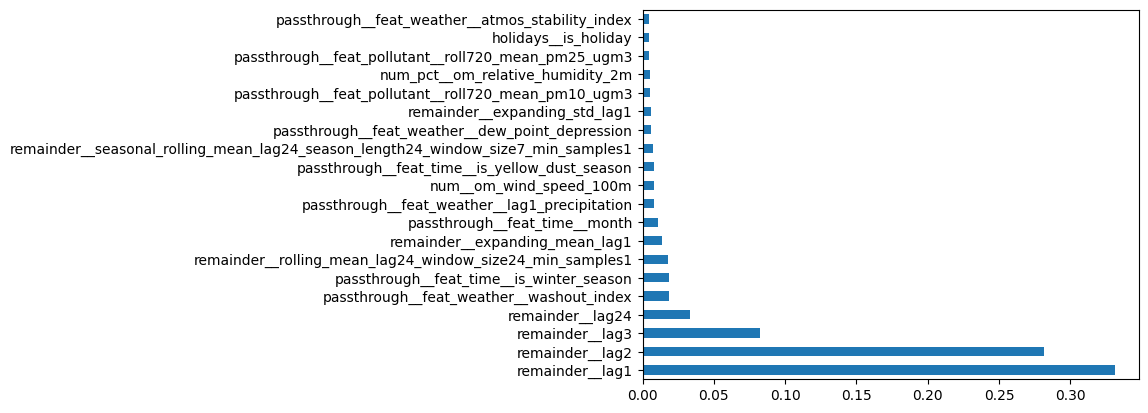

remainder__lag1                                                                     0.331398
remainder__lag2                                                                     0.281426
remainder__lag3                                                                     0.082128
remainder__lag24                                                                    0.033542
passthrough__feat_weather__washout_index                                            0.018451
passthrough__feat_time__is_winter_season                                            0.018333
remainder__rolling_mean_lag24_window_size24_min_samples1                            0.018118
remainder__expanding_mean_lag1                                                      0.013487
passthrough__feat_time__month                                                       0.011129
passthrough__feat_weather__lag1_precipitation                                       0.008078
num__om_wind_speed_100m                                               

In [10]:
# ================================================================
# FIT THE MODEL (ONE PER POLLUTANT)

TARGET_COL = "pm25_ugm3"
# TARGET_COL = "pm10_ugm3"
# TARGET_COL = "no2_ppm"
# TARGET_COL = "o3_ppm"
# TARGET_COL = "so2_ppm"
# TARGET_COL = "co_ppm"
MODEL_NAME = "xgb_" + TARGET_COL

train_ts = custom_xgb.prepare_timeseries_dataframe(train_df, TARGET_COL)
fcst = custom_xgb.create_mlforecaster(train_ts, TARGET_COL)

fcst.fit(
    train_ts,
    static_features=CustomXGBoostModel.STATIC_COLUMNS,
    # weight_col="y_weight_penalty",
)

wrapper = fcst.models_[MODEL_NAME]

# # Access the model inside the pipeline
inner_pipeline = wrapper.pipeline
model = inner_pipeline.named_steps['model']
preprocessor = inner_pipeline.named_steps['preprocessor']

importance = model.feature_importances_
names = preprocessor.get_feature_names_out()

# Sort and plot the top 20
feat_importances = pd.Series(importance, index=names)
feat_importances.nlargest(20).plot(kind='barh')
plt.show()

display(feat_importances.nlargest(500))

In [15]:
# 1. Run the preprocessing step explicitly
# This mimics exactly what happens inside .fit()
processed_df = fcst.preprocess(
    train_ts,
    static_features=CustomXGBoostModel.STATIC_COLUMNS
)

# 2. Compare the IDs in the processed data vs original data
surviving_ids = set(processed_df['unique_id'].unique())
original_ids = set(train_ts['unique_id'].unique())

dropped_ids = original_ids - surviving_ids

print(f"Count dropped: {len(dropped_ids)}")
print(list(dropped_ids))

Count dropped: 14
['2623346_S43', '2623430_S31', '2623214_S31', '2623444_S54', '2623811_S34', '2623198_S54', '2623586_S25', '2622727_S25', '2623367_S33', '2623557_S22', '2623048_S45', '2622950_S39', '2622608_S81', '4953358_S14']


/home/deniscck/.pyenv/versions/openaq-anomaly-prediction/lib/python3.12/site-packages/mlforecast/core.py:434: UserWarning: The following series were dropped completely due to the transformations and features: ['2622608_S81', '2622727_S25', '2622950_S39', '2623048_S45', '2623198_S54', '2623214_S31', ...].
These series won't show up if you use `MLForecast.forecast_fitted_values()`.
You can set `dropna=False` or use transformations that require less samples to mitigate this
  warnings.warn(


In [16]:
with tempfile.TemporaryDirectory() as tmpdir:
    save_dir = os.path.join(cfg.DATA_EXPORT_PATH, 'models')
    fcst.save(save_dir)

#### Predict

In [10]:
custom_xgb = CustomXGBoostModel()

# BigQuery
start_time = time.perf_counter()
query = """
    SELECT
        *
    FROM `openaq-anomaly-prediction.dev_serving.ml_seoul__xgb_features_predictions`
    WHERE datetimeto_utc >= '2025-08-01 15:00:00'
      AND datetimeto_utc <= '2025-12-31 15:00:00'
    ORDER BY location_id, datetimeto_utc ASC
"""
query_parameters = [
    # ("dataset", "STRING", dataset)
]
history_df = bq.query(query, query_parameters=query_parameters, dry_run=False)
custom_xgb.categorize_columns(history_df)

# ================================================================
# INTERPOLATE ALL POLLUTANTS
 
history_df = custom_xgb.interpolate_pollutants(history_df, debug=True)
custom_xgb.print_nan_report(history_df)


# ================================================================
# COLUMNS CATEGORIZATION
 
display(history_df.head(5))
custom_xgb.print_categories_report()

INTERPOLATING 6 POLLUTANTS
----------------------------------------------------------------
BEFORE: 721767 total NaN values
    -> Adding columns       : ['pm25_ugm3_is_imputed', 'pm10_ugm3_is_imputed', 'no2_ppm_is_imputed', 'o3_ppm_is_imputed', 'so2_ppm_is_imputed', 'co_ppm_is_imputed', 'any_imputed']
    -> Grouped by           : ['location_id', 'segment_id']
    -> Linear interpolation : up to 4 hours
    -> Forward fill         : up to 4 hours
    -> Backward fill        : up to 4 hours
AFTER: 671325 total NaN values

[ TARGET    ]: 671325 NaN values in the target columns
pm10_ugm3    113367
no2_ppm      112590
co_ppm       112482
o3_ppm       112199
so2_ppm      112110
pm25_ugm3    108577
dtype: int64

[ OPENAQ    ]: 0 NaN values in OpenAQ columns
[ OPENMETEO ]: 755343 NaN values in OpenMeteo columns
om_elevation                  32841
om_temperature_2m             32841
om_relative_humidity_2m       32841
om_dew_point_2m               32841
om_precipitation              32841
om_

,location_id,datetimeto_utc,concurrent_sensors,segment_id,segment_start,segment_end,segment_perfect_hours,segment_total_hours,segment_perfect_density,segment_tier,segments_num,segments_total,pm25_ugm3,pm10_ugm3,no2_ppm,o3_ppm,so2_ppm,co_ppm,oaq_datetimeto_local,oaq_ismonitor,oaq_owner_id,oaq_provider_id,oaq_latitude,oaq_longitude,om_elevation,om_temperature_2m,om_relative_humidity_2m,om_dew_point_2m,om_precipitation,om_rain,om_snowfall,om_snow_depth,om_shortwave_radiation,om_direct_radiation,om_diffuse_radiation,om_weather_code,om_pressure_msl,om_cloud_cover,om_cloud_cover_low,om_cloud_cover_mid,om_cloud_cover_high,om_vapour_pressure_deficit,om_wind_speed_100m,om_wind_speed_10m,om_wind_direction_10m,om_wind_gusts_10m,om_is_day,feat_time__hour,feat_time__dow,feat_time__month,feat_time__hour_sin_k1,feat_time__hour_cos_k1,feat_time__hour_sin_k2,feat_time__hour_cos_k2,feat_time__hour_sin_k3,feat_time__hour_cos_k3,feat_time__dow_sin_k1,feat_time__dow_cos_k1,feat_time__month_sin_k1,feat_time__month_cos_k1,feat_time__is_rush_hour,feat_time__is_weekend,feat_time__is_party_night,feat_time__is_yellow_dust_season,feat_time__is_moonsoon_season,feat_time__is_winter_season,feat_time__is_summer_break,feat_time__is_winter_break,feat_time__is_spring_break,feat_time__is_school_break,feat_pollutant__expmean_pm25_ugm3,feat_pollutant__expmean_pm10_ugm3,feat_pollutant__expmean_no2_ppm,feat_pollutant__expmean_o3_ppm,feat_pollutant__expmean_so2_ppm,feat_pollutant__expmean_co_ppm,feat_pollutant__roll720_mean_pm25_ugm3,feat_pollutant__roll720_mean_pm10_ugm3,feat_pollutant__roll720_mean_no2_ppm,feat_pollutant__roll720_mean_o3_ppm,feat_pollutant__roll720_mean_so2_ppm,feat_pollutant__roll720_mean_co_ppm,feat_weather__wind_direction_10m_sin,feat_weather__wind_direction_10m_cos,feat_weather__washout_index,feat_weather__moisture_trap_index,feat_weather__atmos_stability_index,feat_weather__moisture_saturation_index,feat_weather__dew_point_depression,feat_weather__photolytic_flux_index,feat_weather__wind_burst_ratio_index_10m,feat_weather__lag1_precipitation,feat_weather__delta1_pressure_msl,feat_weather__delta3_temperature_2m,pm25_ugm3_is_imputed,pm10_ugm3_is_imputed,no2_ppm_is_imputed,o3_ppm_is_imputed,so2_ppm_is_imputed,co_ppm_is_imputed,any_imputed
0,1285353,2025-08-01 15:00:00+00:00,0,1285353_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,2025-08-02 00:00:00,True,4,64,37.5644,126.935,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,<NA>,NaN,<NA>,0,5,7,0.000000,1.000000,0.000000,1.000000e+00,0.000000e+00,1.000000e+00,-0.974928,-0.222521,-0.5,-0.866025,0,1,1,0,1,0,1,0,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,1,1,1,1
1,1285353,2025-08-01 16:00:00+00:00,0,1285353_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,2025-08-02 01:00:00,True,4,64,37.5644,126.935,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,<NA>,NaN,<NA>,1,5,7,0.258819,0.965926,0.500000,8.660254e-01,7.071068e-01,7.071068e-01,-0.974928,-0.222521,-0.5,-0.866025,0,1,1,0,1,0,1,0,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,1,1,1,1
2,1285353,2025-08-01 17:00:00+00:00,0,1285353_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,2025-08-02 02:00:00,True,4,64,37.5644,126.935,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,<NA>,NaN,<NA>,2,5,7,0.500000,0.866025,0.866025,5.000000e-01,1.000000e+00,6.123234e-17,-0.974928,-0.222521,-0.5,-0.866025,0,1,1,0,1,0,1,0,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,1,1,1,1
3,1285353,2025-08-01 18:00:00+00:00,0,1285353_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,2025-08-02 03:00:00,True,4,64,37.5644,126.935,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,NaN,NaN,

COLUMNS CATEGORIZATION

Pollutants columns (6):
['pm25_ugm3', 'pm10_ugm3', 'no2_ppm', 'o3_ppm', 'so2_ppm', 'co_ppm']

OpenAQ columns (6):
['oaq_datetimeto_local', 'oaq_ismonitor', 'oaq_owner_id', 'oaq_provider_id', 'oaq_latitude', 'oaq_longitude']

OpenMeteo columns (23):
['om_elevation', 'om_temperature_2m', 'om_relative_humidity_2m', 'om_dew_point_2m', 'om_precipitation', 'om_rain', 'om_snowfall', 'om_snow_depth', 'om_shortwave_radiation', 'om_direct_radiation', 'om_diffuse_radiation', 'om_weather_code', 'om_pressure_msl', 'om_cloud_cover', 'om_cloud_cover_low', 'om_cloud_cover_mid', 'om_cloud_cover_high', 'om_vapour_pressure_deficit', 'om_wind_speed_100m', 'om_wind_speed_10m', 'om_wind_direction_10m', 'om_wind_gusts_10m', 'om_is_day']

Segments columns (9):
['segment_id', 'segment_start', 'segment_end', 'segment_perfect_hours', 'segment_total_hours', 'segment_perfect_density', 'segment_tier', 'segments_num', 'segments_total']

Features columns (47):
 > Time features (23)      : ['fe

In [20]:
history_df["concurrent_sensors"].value_counts()

concurrent_sensors
6    1309501
0     458320
5      69641
4      16446
1      15869
2       2307
3       1964
Name: count, dtype: Int64

In [11]:
history_df.shape

(467072, 101)

In [12]:
history_df[history_df["om_elevation"].isna()].head()

,location_id,datetimeto_utc,concurrent_sensors,segment_id,segment_start,segment_end,segment_perfect_hours,segment_total_hours,segment_perfect_density,segment_tier,segments_num,segments_total,pm25_ugm3,pm10_ugm3,no2_ppm,o3_ppm,so2_ppm,co_ppm,oaq_datetimeto_local,oaq_ismonitor,oaq_owner_id,oaq_provider_id,oaq_latitude,oaq_longitude,om_elevation,om_temperature_2m,om_relative_humidity_2m,om_dew_point_2m,om_precipitation,om_rain,om_snowfall,om_snow_depth,om_shortwave_radiation,om_direct_radiation,om_diffuse_radiation,om_weather_code,om_pressure_msl,om_cloud_cover,om_cloud_cover_low,om_cloud_cover_mid,om_cloud_cover_high,om_vapour_pressure_deficit,om_wind_speed_100m,om_wind_speed_10m,om_wind_direction_10m,om_wind_gusts_10m,om_is_day,feat_time__hour,feat_time__dow,feat_time__month,feat_time__hour_sin_k1,feat_time__hour_cos_k1,feat_time__hour_sin_k2,feat_time__hour_cos_k2,feat_time__hour_sin_k3,feat_time__hour_cos_k3,feat_time__dow_sin_k1,feat_time__dow_cos_k1,feat_time__month_sin_k1,feat_time__month_cos_k1,feat_time__is_rush_hour,feat_time__is_weekend,feat_time__is_party_night,feat_time__is_yellow_dust_season,feat_time__is_moonsoon_season,feat_time__is_winter_season,feat_time__is_summer_break,feat_time__is_winter_break,feat_time__is_spring_break,feat_time__is_school_break,feat_pollutant__expmean_pm25_ugm3,feat_pollutant__expmean_pm10_ugm3,feat_pollutant__expmean_no2_ppm,feat_pollutant__expmean_o3_ppm,feat_pollutant__expmean_so2_ppm,feat_pollutant__expmean_co_ppm,feat_pollutant__roll720_mean_pm25_ugm3,feat_pollutant__roll720_mean_pm10_ugm3,feat_pollutant__roll720_mean_no2_ppm,feat_pollutant__roll720_mean_o3_ppm,feat_pollutant__roll720_mean_so2_ppm,feat_pollutant__roll720_mean_co_ppm,feat_weather__wind_direction_10m_sin,feat_weather__wind_direction_10m_cos,feat_weather__washout_index,feat_weather__moisture_trap_index,feat_weather__atmos_stability_index,feat_weather__moisture_saturation_index,feat_weather__dew_point_depression,feat_weather__photolytic_flux_index,feat_weather__wind_burst_ratio_index_10m,feat_weather__lag1_precipitation,feat_weather__delta1_pressure_msl,feat_weather__delta3_temperature_2m,pm25_ugm3_is_imputed,pm10_ugm3_is_imputed,no2_ppm_is_imputed,o3_ppm_is_imputed,so2_ppm_is_imputed,co_ppm_is_imputed,any_imputed
0,1285353,2025-08-01 15:00:00+00:00,0,1285353_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,2025-08-02 00:00:00,True,4,64,37.5644,126.935,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,<NA>,NaN,<NA>,0,5,7,0.000000,1.000000,0.000000,1.000000e+00,0.000000e+00,1.000000e+00,-0.974928,-0.222521,-0.5,-0.866025,0,1,1,0,1,0,1,0,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,1,1,1,1
1,1285353,2025-08-01 16:00:00+00:00,0,1285353_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,2025-08-02 01:00:00,True,4,64,37.5644,126.935,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,<NA>,NaN,<NA>,1,5,7,0.258819,0.965926,0.500000,8.660254e-01,7.071068e-01,7.071068e-01,-0.974928,-0.222521,-0.5,-0.866025,0,1,1,0,1,0,1,0,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,1,1,1,1
2,1285353,2025-08-01 17:00:00+00:00,0,1285353_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,2025-08-02 02:00:00,True,4,64,37.5644,126.935,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,<NA>,NaN,<NA>,2,5,7,0.500000,0.866025,0.866025,5.000000e-01,1.000000e+00,6.123234e-17,-0.974928,-0.222521,-0.5,-0.866025,0,1,1,0,1,0,1,0,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,1,1,1,1,1,1
3,1285353,2025-08-01 18:00:00+00:00,0,1285353_serie,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,2025-08-02 03:00:00,True,4,64,37.5644,126.935,NaN,NaN,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,NaN,<NA>,<NA>,<NA>,<NA>,NaN,NaN,

In [ ]:
# saved_parquet = os.path.join(cfg.DATA_EXPORT_PATH, 'ml_seoul__xgb_features_no_segments.parquet')

# con = duckdb.connect()
# history_df = con.execute(
#     f""
# )

# query = f"""
#     SELECT *
#     FROM read_parquet('{saved_parquet}')
#     WHERE oaq_datetimeto_local >= '2025-09-01'
#       AND oaq_datetimeto_local <= '2025-10-31 23:00:00'
#     ORDER BY location_id, oaq_datetimeto_local ASC
# """
# history_df = con.execute(query, {

# }).df()

In [ ]:
# history_df.to_parquet(saved_parquet, index=False, compression='snappy')

In [9]:
history_df.dropna().info()

<class 'pandas.core.frame.DataFrame'>
Index: 0 entries
Columns: 101 entries, location_id to any_imputed
dtypes: Int64(30), boolean(1), datetime64[us, UTC](1), datetime64[us](1), float64(57), int64(7), object(4)
memory usage: 0.0+ bytes


In [54]:
# history_df.info(verbose=True, show_counts=True)

In [52]:
history_df.isna().sum().sum()

np.int64(2446268)

In [56]:
display(history_df["pm25_ugm3"].isna().sum())
display(history_df["pm10_ugm3"].isna().sum())

np.int64(54242)

np.int64(50655)

In [19]:
# 1. Sort is CRITICAL. 
# We need time to be sequential, and IDs to be grouped together.
df = history_df.sort_values(by=['location_id', 'datetimeto_utc']).copy()

# 2. Identify all numerical columns (pollutants + features)
# Exclude your ID and Time columns
feature_cols = df.select_dtypes(include=np.number).columns.tolist()

cols_to_exclude = ['location_id', 'datetimeto_utc']
feature_cols = [c for c in feature_cols if c not in cols_to_exclude]

print(f"Interpolating {len(feature_cols)} columns...")

# 3. Apply Grouped Interpolation
# This applies the logic to all 100+ columns at once per group.
df[feature_cols] = df.groupby('location_id')[feature_cols].transform(
    lambda x: x.interpolate(method='linear', limit=24, limit_direction='both')
)

# 4. Trailing Edge Fill
df[feature_cols] = df.groupby('location_id')[feature_cols].transform(
    lambda x: x.ffill(limit=12)
)

Interpolating 108 columns...


In [34]:
save_dir = os.path.join(cfg.DATA_EXPORT_PATH, 'models')
loaded_fcst = MLForecast.load(save_dir)

In [35]:
history_df["datetimeto_utc"].max()

Timestamp('2025-10-31 14:00:00+0000', tz='UTC')

<Axes: xlabel='datetimeto_utc', ylabel='pm25_ugm3'>

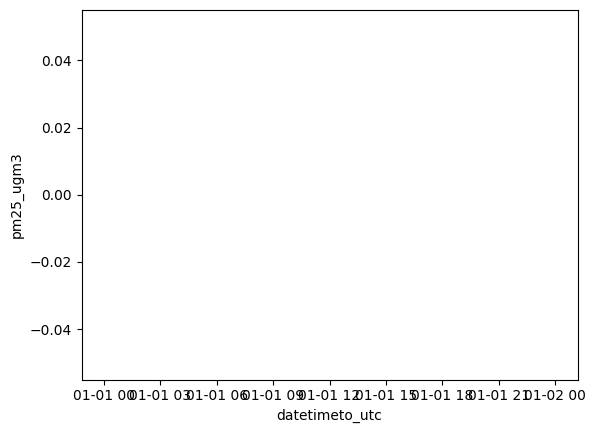

In [57]:
sns.lineplot(data=history_df[history_df["location_id"] == "6136410"], x="datetimeto_utc", y="pm25_ugm3")

In [ ]:
TARGET_COL = "pm25_ugm3"
# TARGET_COL = "pm10_ugm3"
# TARGET_COL = "no2_ppm"
# TARGET_COL = "o3_ppm"
# TARGET_COL = "so2_ppm"
# TARGET_COL = "co_ppm"
MODEL_NAME = "xgb_" + TARGET_COL

prepped_ts = custom_xgb.prepare_timeseries_dataframe(history_df, TARGET_COL)
prepped_ts.tail(10)
# prepped_ts["y"].isna().sum()
# prepped_ts["y"].info()

In [ ]:
# ================================================================
# PREDICT

history_df["location_id"]

# new_data => the historical full data up to now
# X_df => separate DF containing the future 72 timestamps + all the exogenous columns

# Minimum Training (before lags): Total_Length - h - ((n_windows-1) * step_size)

# Setup for 336h segments (14 days)
# prediction_setup = {"h": 24, "n_windows": 4, "step_size": 24}  # => 216h training (3/4 windows)
# prediction_setup = {"h": 24, "n_windows": 3, "step_size": 24}  # => 216h training (3/4 windows)
# prediction_setup = {"h": 72, "n_windows": 2, "step_size": 48}  # => 216h training
prediction_setup = {
    "h": 72,
    "n_windows": 3,
    "step_size": 24,
}  # => 216h training
# prediction_setup = {"h": 168, "n_windows": 1, "step_size": 168}  # => 168h training (stress test)

# Setup for 504h segments (21 days)
prediction_setup = {"h": 72, "n_windows": 4, "step_size": 24}

new_df = history_df
predictions = loaded_fcst.predict(
    h=72,
    X_df=history_df,
)

ValueError: X_df must have 'unique_id' and 'ds' columns.